In [ ]:

from tensorflow.keras.layers import Conv2D,  Activation, MaxPool2D, Conv2DTranspose
from tensorflow.keras.layers import Input,BatchNormalization, MaxPooling2D
from tensorflow.keras.layers import concatenate, Concatenate, Input
from tensorflow.keras.callbacks import ModelCheckpoint, LearningRateScheduler
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.layers import Input, DepthwiseConv2D
from tensorflow.keras.layers import ReLU, AvgPool2D, Flatten, Dense#,sigmoid
from tensorflow.keras.activations import sigmoid
from tensorflow.keras.layers import UpSampling2D
# from tensorflow.keras import Model
from tensorflow.keras import layers
import tensorflow_io as tfio
import tensorflow.keras.backend as K
from tensorflow.keras import activations
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping
from tensorflow.keras.losses import binary_crossentropy,mse
from tensorflow.keras.layers import ZeroPadding2D, Concatenate,Add,SpatialDropout2D
from tensorflow import keras
import tensorflow_wavelets.Layers.DWT as DWT
import tensorflow_wavelets.Layers.DTCWT as DTCWT
import tensorflow_wavelets.Layers.DMWT as DMWT

# Custom Activation function Layer
# import tensorflow_wavelets.Layers.Threshold as Threshold
import tensorflow.keras.backend as K
# import tensorflow as tf

from keras.utils.vis_utils import plot_model
from keras.models import  model_from_json
from keras.optimizers import Adam
from keras.layers import ELU, PReLU, LeakyReLU
# from morpholayers import *
# from morpholayers.layers import Dilation2D,Erosion2D,Closing2D,Opening2D,reconstruction_dilation,reconstruction_erosion
import scipy
import matplotlib.pyplot as plt
import cv2
import numpy as np

import PIL
from io import StringIO
from tqdm import tqdm

from __future__ import absolute_import
from __future__ import division
from __future__ import print_function



from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.model_selection import StratifiedKFold

import matplotlib.pyplot as plt
from matplotlib import pylab as plt
from matplotlib.colors import LinearSegmentedColormap

from collections import Counter
# from sklearn.model_selection import StratifiedKFold

# import albumentations as A

import glob, random, os, warnings
import matplotlib.pyplot as plt
# from keras.callbacks import ModelCheckpoint, EarlyStopping
# import seaborn as sns

from cv2 import imread

import pywt
import pywt.data

# from morpholayers import *
# from morpholayers.layers import Dilation2D,Erosion2D,Closing2D,Opening2D,reconstruction_dilation
import time
from collections import Counter

# import albumentations as A
import glob, random, os, warnings




# print(tf.__version__)

from functools import partial
import numpy as np
import pandas as pd
import json
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau, CSVLogger, TensorBoard
# print(tf.__version__)

In [ ]:
print("hello")

hello


In [ ]:
import tensorflow as tf
import numpy as np
import os
from sklearn.model_selection import train_test_split

from tensorflow.keras.layers import Layer
import tensorflow as tf




# ===== Paths =====
image_dir = "/workspace/bhagvan/July2023/image_splicing/Bernard/Computer_Vision/spliced_NIST/rgb_imgs"
mask_dir  = "/workspace/bhagvan/July2023/image_splicing/Bernard/Computer_Vision/spliced_NIST/masks"

image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.png')])
mask_files  = [f.replace('rgb.png', 'mask.png') for f in image_files]

image_paths = [os.path.join(image_dir, f) for f in image_files]
mask_paths  = [os.path.join(mask_dir, f) for f in mask_files]

# ===== Split =====
train_imgs, temp_imgs, train_masks, temp_masks = train_test_split(image_paths, mask_paths, test_size=0.3, random_state=42)
val_imgs, test_imgs, val_masks, test_masks = train_test_split(temp_imgs, temp_masks, test_size=0.5, random_state=42)

# ===== Parameters =====
IMG_SIZE = (256, 256)

def parse_image(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, IMG_SIZE)
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = 1.0 - mask  # Optional: invert mask
    return img, mask

def build_dataset(img_list, mask_list, batch_size=2, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((img_list, mask_list))
    ds = ds.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

def dataset_to_numpy(ds):
    x_list, y_list = [], []
    for batch_x, batch_y in ds:
        x_list.append(batch_x.numpy())
        y_list.append(batch_y.numpy())
    x = np.concatenate(x_list, axis=0)
    y = np.concatenate(y_list, axis=0)
    return x, y

# ===== Build datasets =====
train_ds = build_dataset(train_imgs, train_masks)
val_ds   = build_dataset(val_imgs, val_masks, shuffle=False)
test_ds  = build_dataset(test_imgs, test_masks, shuffle=False)

# ===== Convert to NumPy =====
train_x, train_y = dataset_to_numpy(train_ds)
val_x, val_y     = dataset_to_numpy(val_ds)
test_x, test_y   = dataset_to_numpy(test_ds)

# ===== Sanity check =====
print("✅ train_x:", train_x.shape)  # (N, 256, 256, 3)
print("✅ train_y:", train_y.shape)  # (N, 256, 256, 1)


✅ train_x: (9429, 256, 256, 3)
✅ train_y: (9429, 256, 256, 1)


In [ ]:
import tensorflow as tf
from tensorflow.keras.layers import (
    Layer, Input, Conv2D, DepthwiseConv2D, BatchNormalization, Activation,
    Add, MaxPooling2D, UpSampling2D, Concatenate, Dropout
)
from tensorflow.keras.models import Model





class MultiScaleDilatedBlock(Layer):
    """Parallel atrous convs, concatenated then projected back to C."""
    def __init__(self, dilations=(1,2,4,8), **kwargs):
        super().__init__(**kwargs)
        self.dils = dilations

    def build(self, input_shape):
        C = input_shape[-1]
        self.branches = [Conv2D(C, 3, dilation_rate=d, padding="same", activation="relu")
                         for d in self.dils]
        self.proj = Conv2D(C, 1, padding="same")  # project back to C

    def call(self, x):
        feats = [b(x) for b in self.branches]
        y = Concatenate()(feats)
        y = self.proj(y)
        return Add()([x, y])


import tensorflow as tf
from tensorflow.keras.layers import Conv2D, Multiply, Add
from tensorflow.keras.layers import (Input, Conv2D, UpSampling2D, Concatenate, BatchNormalization,
                                     Dropout, Activation, Add, Lambda)
from tensorflow.keras.models import Model
import tensorflow as tf

# Lightweight ViT block for demonstration
class SimpleViTBlock(tf.keras.layers.Layer):
    def __init__(self, num_heads, embed_dim):
        super().__init__()
        self.mha = tf.keras.layers.MultiHeadAttention(num_heads, embed_dim // num_heads)
        self.norm1 = tf.keras.layers.LayerNormalization()
        self.norm2 = tf.keras.layers.LayerNormalization()
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(embed_dim*4, activation="gelu"),
            tf.keras.layers.Dense(embed_dim)
        ])
    def call(self, x):
        h = self.norm1(x)
        h = self.mha(h, h)
        x = x + h
        h = self.norm2(x)
        h = self.ffn(h)
        return x + h

# Example EdgeAttentionBlock - define or import your own as needed
from tensorflow.keras.layers import DepthwiseConv2D

import tensorflow as tf
from tensorflow.keras.layers import DepthwiseConv2D, Conv2D
import tensorflow as tf
from tensorflow.keras.layers import (Input, Conv2D, UpSampling2D, Concatenate, BatchNormalization,
                                     Dropout, Activation)
from tensorflow.keras.models import Model

# Lightweight ViT block for demonstration
class SimpleViTBlock(tf.keras.layers.Layer):
    def __init__(self, num_heads, embed_dim):
        super().__init__()
        self.mha = tf.keras.layers.MultiHeadAttention(num_heads, embed_dim // num_heads)
        self.norm1 = tf.keras.layers.LayerNormalization()
        self.norm2 = tf.keras.layers.LayerNormalization()
        self.ffn = tf.keras.Sequential([
            tf.keras.layers.Dense(embed_dim*4, activation="gelu"),
            tf.keras.layers.Dense(embed_dim)
        ])
    def call(self, x):
        h = self.norm1(x)
        h = self.mha(h, h)
        x = x + h
        h = self.norm2(x)
        h = self.ffn(h)
        return x + h

from tensorflow.keras.layers import DepthwiseConv2D

class EdgeAttentionBlock(tf.keras.layers.Layer):
    def __init__(self, filters, **kwargs):
        super().__init__(**kwargs)
        kernel = [[-1, -1, -1],
                  [-1,  8, -1],
                  [-1, -1, -1]]
        self.kernel_np = tf.constant(kernel, dtype=tf.float32)
        self.filters = filters
        self.attn_conv = Conv2D(filters, 1, activation="sigmoid")

    def build(self, input_shape):
        channel_count = input_shape[-1]
        kernel = tf.tile(self.kernel_np[:, :, tf.newaxis, tf.newaxis], [1, 1, channel_count, 1])
        self.depth_conv = DepthwiseConv2D(
            kernel_size=3,
            padding="same",
            use_bias=False,
            depthwise_initializer=tf.constant_initializer(kernel.numpy()),
            trainable=False
        )

    def call(self, x):
        edge = tf.abs(self.depth_conv(x))
        attn = self.attn_conv(edge)
        return x * attn



class EdgeRefinementBlock(Layer):
    """Injects Sobel edge cues; shape-preserving."""
    def __init__(self, **kwargs):
        super().__init__(**kwargs)

    def build(self, input_shape):
        C = input_shape[-1]
        self.conv_edge = Conv2D(C, 3, padding="same", activation="relu")
        self.fuse = Conv2D(C, 1, padding="same")

    def call(self, x):
        sob = tf.image.sobel_edges(x)          # B,H,W,C,2
        sob = tf.norm(sob, axis=-1)            # B,H,W,C
        e = self.conv_edge(sob)
        y = self.fuse(Add()([x, e]))
        return y

def build_transeanet_seg_model(
        input_shape=(256, 256, 3),
        patch_size=16,
        embed_dim=128,
        num_heads=4,
        vit_depth=3,
        c_filters=[64, 128, 256],
        output_channels=3,        # Set to 3 for RGB, or any other desired number of channels
        output_activation='sigmoid'  # Set to 'sigmoid', 'tanh', or None per use-case
    ):
    inp = Input(shape=input_shape)

    # CNN backbone
    x_cnn = Conv2D(32, 3, padding="same", activation="relu")(inp)
    x_cnn = Conv2D(c_filters[0], 3, strides=2, padding="same", activation="relu")(x_cnn)
    x_cnn = BatchNormalization()(x_cnn)
    x_cnn = Conv2D(c_filters[1], 3, strides=2, padding="same", activation="relu")(x_cnn)
    x_cnn = BatchNormalization()(x_cnn)
    x_cnn=MultiScaleDilatedBlock()(x_cnn)
#     (x_cnn)=EdgeRefinementBlock()(x_cnn)
    x_cnn = Conv2D(c_filters[2], 3, strides=2, padding="same", activation="relu")(x_cnn)
    x_cnn = BatchNormalization()(x_cnn)

    # Patch embedding for ViT
    x_patch = Conv2D(embed_dim, (patch_size, patch_size), strides=patch_size, padding="valid")(inp)
    ph, pw = input_shape[0] // patch_size, input_shape[1] // patch_size
    x_patch = tf.reshape(x_patch, [-1, ph * pw, embed_dim])

    for _ in range(vit_depth):
        x_patch = SimpleViTBlock(num_heads, embed_dim)(x_patch)
    x_vit = tf.reshape(x_patch, [-1, ph, pw, embed_dim])
    x_vit = UpSampling2D(size=(8, 8))(x_vit)

    x_cnn_upsampled = UpSampling2D(size=(4, 4))(x_cnn)
    x = Concatenate()([x_cnn_upsampled, x_vit])
    x = EdgeAttentionBlock(384)(x)
    x = Conv2D(128, 3, padding="same", activation="relu")(x)

    x = UpSampling2D(size=(2, 2))(x)
    x = Conv2D(64, 3, padding='same', activation='relu')(x)
    x = UpSampling2D(size=(2, 2))(x)
    x = Conv2D(32, 3, padding='same', activation='relu')(x)
    x = UpSampling2D(size=(2, 2))(x)
    x = Conv2D(16, 3, padding='same',strides=2, activation='relu')(x)
    x = Conv2D(32, 3, padding='same', strides=2,activation='relu')(x)
    # Output: shape = input, only channels changed
    out = Conv2D(1, 1, activation='sigmoid')(x)
    # Output: (batch, 256, 256, output_channels)

    return Model(inputs=inp, outputs=out)

# Usage example for RGB reconstruction
# model = build_hybrid_model(input_shape=(256,256,3), output_channels=3)
# model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
# model.summary()



# -------------------------------
# def build_transeanet_seg_model(input_shape=(256, 256, 3), base_ch=32):

# -------------------------------
# Losses (unchanged)
# -------------------------------
def dice_loss(y_true, y_pred, smooth=1e-6):
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])
    intersect = tf.reduce_sum(y_true_f * y_pred_f)
    return 1 - (2. * intersect + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def bce_dice_loss(y_true, y_pred):
    return tf.keras.losses.binary_crossentropy(y_true, y_pred) + dice_loss(y_true, y_pred)

def tamper_loss(y_true, y_pred):
    # y_true/y_pred: [tamper_mask, boundary]
    seg_true, boundary_true = y_true
    seg_pred, boundary_pred = y_pred
    seg_loss = bce_dice_loss(seg_true, seg_pred)
    bound_loss = tf.keras.losses.binary_crossentropy(boundary_true, boundary_pred)
    return seg_loss + 0.5 * bound_loss


# -------------------------------
# Example usage
# -------------------------------
# if __name__ == "__main__":
#     model = build_transeanet_seg_model(input_shape=(256, 256, 3), base_ch=32)
#     model.compile(
#         optimizer="adam",
#         loss={"tamper_mask": bce_dice_loss, "boundary": "binary_crossentropy"},
#         metrics={"tamper_mask": ["accuracy"], "boundary": ["accuracy"]},
#     )
#     model.summary()


In [ ]:
# Build and compile the model
model = build_transeanet_seg_model()

import tensorflow as tf
import pandas as pd
import os

# 📁 Create directories
os.makedirs("transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 trained_models", exist_ok=True)
os.makedirs("transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 training_logs", exist_ok=True)

# 🎯 Custom Losses


import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.metrics import (
    BinaryAccuracy, Precision, Recall, AUC,
    TruePositives, TrueNegatives, FalsePositives, FalseNegatives
)

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.metrics import (
    BinaryAccuracy, Precision, Recall, AUC,
    TruePositives, TrueNegatives, FalsePositives, FalseNegatives
)

# Custom IoU Metric
class MeanIoU(tf.keras.metrics.Metric):
    def __init__(self, name="iou", threshold=0.5, **kwargs):
        super(MeanIoU, self).__init__(name=name, **kwargs)
        self.threshold = threshold
        self.intersection = self.add_weight(name="intersection", initializer="zeros")
        self.union = self.add_weight(name="union", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred = tf.cast(y_pred > self.threshold, tf.float32)
        y_true = tf.cast(y_true, tf.float32)

        intersection = tf.reduce_sum(y_true * y_pred)
        union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection

        self.intersection.assign_add(intersection)
        self.union.assign_add(union)

    def result(self):
        return tf.math.divide_no_nan(self.intersection, self.union)

    def reset_states(self):
        self.intersection.assign(0.0)
        self.union.assign(0.0)

# Custom F1 Score
class F1Score(tf.keras.metrics.Metric):
    def __init__(self, name="f1_score", threshold=0.5, **kwargs):
        super(F1Score, self).__init__(name=name, **kwargs)
        self.threshold = threshold
        self.tp = self.add_weight(name="tp", initializer="zeros")
        self.fp = self.add_weight(name="fp", initializer="zeros")
        self.fn = self.add_weight(name="fn", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred = tf.cast(y_pred > self.threshold, tf.float32)
        y_true = tf.cast(y_true, tf.float32)

        tp = tf.reduce_sum(y_true * y_pred)
        fp = tf.reduce_sum((1 - y_true) * y_pred)
        fn = tf.reduce_sum(y_true * (1 - y_pred))

        self.tp.assign_add(tp)
        self.fp.assign_add(fp)
        self.fn.assign_add(fn)

    def result(self):
        precision = tf.math.divide_no_nan(self.tp, self.tp + self.fp)
        recall = tf.math.divide_no_nan(self.tp, self.tp + self.fn)
        f1 = 2 * tf.math.divide_no_nan(precision * recall, precision + recall)
        return f1

    def reset_states(self):
        self.tp.assign(0.0)
        self.fp.assign(0.0)
        self.fn.assign(0.0)


import tensorflow as tf

def iou_bce_loss(y_true, y_pred, smooth=1e-6):
    # Flatten tensors for calculation
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    # Binary Crossentropy
    bce = tf.keras.losses.binary_crossentropy(y_true_f, y_pred_f)
    bce_loss = tf.reduce_mean(bce)

    # Intersection Over Union (IoU)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    total = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    union = total - intersection
    iou = (intersection + smooth) / (union + smooth)
    iou_loss = 1 - iou

    # Combined loss
    return bce_loss + iou_loss

#  Loss function dictionary
# loss_functions = {


#     "local_noise_inconsistency_loss": local_noise_inconsistency_loss
# }

# 🧠 Learning Rate Scheduling
initial_lr = 1e-3
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=initial_lr,
    decay_steps=5000,
    decay_rate=0.9,
    staircase=True
)

def custom_lr_schedule(epoch):
    if epoch < 10:
        return initial_lr
    else:
        return initial_lr * tf.math.exp(-0.1 * (epoch - 10))

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1,
    min_lr=1e-6
)

lr_scheduler = tf.keras.callbacks.LearningRateScheduler(custom_lr_schedule, verbose=1)

# OLD (remove or comment this)
# lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(...)

# NEW
initial_lr = 1e-3
optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)




    # Assign model with a name internally
# model = mobilnet_skip()



#  Save model
# pd.DataFrame(history.history).to_excel(f"/workspace/bhagvan/July2023/image_splicing/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 local_noise_inconsistency_loss trained_models/21-07-2025 densnet sobel training_log.xlsx", index=False)
# model.save(f"/workspace/bhagvan/July2023/image_splicing/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 trained_models/model_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 local_noise_inconsistency_loss.h5")
model.compile(
    optimizer=optimizer,
    loss=iou_bce_loss,
       metrics=[
    'accuracy',
    Precision(name='precision'),
    Recall(name='recall'),
    AUC(name='auc'),
    TruePositives(name='tp'),
    TrueNegatives(name='tn'),
    FalsePositives(name='fp'),
    FalseNegatives(name='fn'),
    MeanIoU(name='iou') , # Custom IoU,
           F1Score(name='f1_score')
]    )

# model.summary()

history = model.fit(
    train_x, train_y, validation_data=(val_x, val_y),
    epochs=100,
    callbacks=[reduce_lr, lr_scheduler],
    batch_size=8,
    verbose=1
)



Epoch 1: LearningRateScheduler setting learning rate to 0.001.
Epoch 1/100


2025-08-21 13:15:50.186014: I tensorflow/compiler/xla/stream_executor/cuda/cuda_dnn.cc:428] Loaded cuDNN version 8700
2025-08-21 13:15:50.374913: I tensorflow/compiler/xla/stream_executor/cuda/cuda_blas.cc:648] TensorFloat-32 will be used for the matrix multiplication. This will only be logged once.
2025-08-21 13:15:50.717383: I tensorflow/compiler/xla/service/service.cc:173] XLA service 0x7f7d3a680530 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
2025-08-21 13:15:50.717433: I tensorflow/compiler/xla/service/service.cc:181]   StreamExecutor device (0): NVIDIA A100-SXM4-40GB, Compute Capability 8.0
2025-08-21 13:15:50.721735: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
2025-08-21 13:15:50.837510: I tensorflow/compiler/jit/xla_compilation_cache.cc:480] Compiled cluster using XLA!  This line is logged at most once for the lifetime of th

1179/1179 [==============================] - ETA: 0s - loss: 0.7975 - accuracy: 0.9531 - precision: 0.5838 - recall: 0.5154 - auc: 0.9052 - tp: 16730325.0000 - tn: 573549440.0000 - fp: 11926369.0000 - fn: 15732824.0000 - iou: 0.3715 - f1_score: 0.5418

/usr/local/lib/python3.8/dist-packages/keras/engine/training.py:2416: UserWarning: Metric MeanIoU implements a `reset_states()` method; rename it to `reset_state()` (without the final "s"). The name `reset_states()` has been deprecated to improve API consistency.
  m.reset_state()
/usr/local/lib/python3.8/dist-packages/keras/engine/training.py:2416: UserWarning: Metric F1Score implements a `reset_states()` method; rename it to `reset_state()` (without the final "s"). The name `reset_states()` has been deprecated to improve API consistency.
  m.reset_state()


1179/1179 [==============================] - 140s 107ms/step - loss: 0.7975 - accuracy: 0.9531 - precision: 0.5838 - recall: 0.5154 - auc: 0.9052 - tp: 16730325.0000 - tn: 573549440.0000 - fp: 11926369.0000 - fn: 15732824.0000 - iou: 0.3715 - f1_score: 0.5418 - val_loss: 0.9135 - val_accuracy: 0.9263 - val_precision: 0.3934 - val_recall: 0.6516 - val_auc: 0.9008 - val_tp: 4519435.0000 - val_tn: 118477464.0000 - val_fp: 6969260.0000 - val_fn: 2416572.0000 - val_iou: 0.3163 - val_f1_score: 0.4806 - lr: 0.0010

Epoch 2: LearningRateScheduler setting learning rate to 0.001.
Epoch 2/100
1179/1179 [==============================] - 120s 102ms/step - loss: 0.6681 - accuracy: 0.9627 - precision: 0.6890 - recall: 0.6123 - auc: 0.9278 - tp: 19877340.0000 - tn: 576501632.0000 - fp: 8973987.0000 - fn: 12585825.0000 - iou: 0.4747 - f1_score: 0.6438 - val_loss: 0.9072 - val_accuracy: 0.9110 - val_precision: 0.3601 - val_recall: 0.8104 - val_auc: 0.9489 - val_tp: 5620979.0000 - val_tn: 115457560.0000


Epoch 15: LearningRateScheduler setting learning rate to 0.0006703200633637607.
Epoch 15/100
1179/1179 [==============================] - 121s 103ms/step - loss: 0.1812 - accuracy: 0.9892 - precision: 0.9526 - recall: 0.8936 - auc: 0.9792 - tp: 29008046.0000 - tn: 584032640.0000 - fp: 1443436.0000 - fn: 3455089.0000 - iou: 0.8606 - f1_score: 0.9251 - val_loss: 0.3440 - val_accuracy: 0.9822 - val_precision: 0.9267 - val_recall: 0.7672 - val_auc: 0.9402 - val_tp: 5321646.0000 - val_tn: 125025696.0000 - val_fp: 421020.0000 - val_fn: 1614361.0000 - val_iou: 0.7292 - val_f1_score: 0.8434 - lr: 6.7032e-04

Epoch 16: LearningRateScheduler setting learning rate to 0.0006065306952223182.
Epoch 16/100
1179/1179 [==============================] - 122s 103ms/step - loss: 0.1683 - accuracy: 0.9898 - precision: 0.9566 - recall: 0.9011 - auc: 0.9804 - tp: 29251420.0000 - tn: 584148992.0000 - fp: 1326348.0000 - fn: 3211723.0000 - iou: 0.8712 - f1_score: 0.9312 - val_loss: 0.3242 - val_accuracy: 0.982

... (2 outputs left out)


Epoch 52: LearningRateScheduler setting learning rate to 1.657267966947984e-05.
Epoch 52/100
1179/1179 [==============================] - 121s 102ms/step - loss: 0.0736 - accuracy: 0.9935 - precision: 0.9851 - recall: 0.9463 - auc: 0.9905 - tp: 30718544.0000 - tn: 585012224.0000 - fp: 463505.0000 - fn: 1744591.0000 - iou: 0.9446 - f1_score: 0.9715 - val_loss: 0.2869 - val_accuracy: 0.9853 - val_precision: 0.9463 - val_recall: 0.8160 - val_auc: 0.9374 - val_tp: 5660082.0000 - val_tn: 125125816.0000 - val_fp: 320928.0000 - val_fn: 1275925.0000 - val_iou: 0.7866 - val_f1_score: 0.8806 - lr: 1.6573e-05

Epoch 53: LearningRateScheduler setting learning rate to 1.4995581295806915e-05.
Epoch 53/100
1179/1179 [==============================] - 120s 102ms/step - loss: 0.0735 - accuracy: 0.9935 - precision: 0.9852 - recall: 0.9464 - auc: 0.9906 - tp: 30722204.0000 - tn: 585013120.0000 - fp: 463056.0000 - fn: 1740949.0000 - iou: 0.9447 - f1_score: 0.9716 - val_loss: 0.2843 - val_accuracy: 0.9853


Epoch 64: LearningRateScheduler setting learning rate to 4.991593414160889e-06.
Epoch 64/100
1179/1179 [==============================] - 121s 103ms/step - loss: 0.0727 - accuracy: 0.9936 - precision: 0.9854 - recall: 0.9467 - auc: 0.9906 - tp: 30733676.0000 - tn: 585021632.0000 - fp: 453911.0000 - fn: 1729482.0000 - iou: 0.9454 - f1_score: 0.9720 - val_loss: 0.2869 - val_accuracy: 0.9853 - val_precision: 0.9468 - val_recall: 0.8156 - val_auc: 0.9368 - val_tp: 5656800.0000 - val_tn: 125128944.0000 - val_fp: 317808.0000 - val_fn: 1279207.0000 - val_iou: 0.7869 - val_f1_score: 0.8807 - lr: 4.9916e-06

Epoch 65: LearningRateScheduler setting learning rate to 4.51658070232952e-06.
Epoch 65/100
1179/1179 [==============================] - 121s 103ms/step - loss: 0.0724 - accuracy: 0.9936 - precision: 0.9855 - recall: 0.9467 - auc: 0.9906 - tp: 30731254.0000 - tn: 585024064.0000 - fp: 451398.0000 - fn: 1731902.0000 - iou: 0.9455 - f1_score: 0.9720 - val_loss: 0.2875 - val_accuracy: 0.9853 -


Epoch 76: LearningRateScheduler setting learning rate to 1.5034391935841995e-06.
Epoch 76/100
1179/1179 [==============================] - 121s 102ms/step - loss: 0.0723 - accuracy: 0.9936 - precision: 0.9856 - recall: 0.9468 - auc: 0.9906 - tp: 30736864.0000 - tn: 585027328.0000 - fp: 448830.0000 - fn: 1726301.0000 - iou: 0.9458 - f1_score: 0.9721 - val_loss: 0.2876 - val_accuracy: 0.9853 - val_precision: 0.9467 - val_recall: 0.8150 - val_auc: 0.9366 - val_tp: 5653078.0000 - val_tn: 125128728.0000 - val_fp: 317978.0000 - val_fn: 1282929.0000 - val_iou: 0.7863 - val_f1_score: 0.8804 - lr: 1.5034e-06

Epoch 77: LearningRateScheduler setting learning rate to 1.3603681736640283e-06.
Epoch 77/100
1179/1179 [==============================] - 121s 102ms/step - loss: 0.0723 - accuracy: 0.9936 - precision: 0.9856 - recall: 0.9467 - auc: 0.9906 - tp: 30734196.0000 - tn: 585026560.0000 - fp: 448963.0000 - fn: 1728955.0000 - iou: 0.9457 - f1_score: 0.9721 - val_loss: 0.2869 - val_accuracy: 0.985


Epoch 89: LearningRateScheduler setting learning rate to 4.0973492332341266e-07.
Epoch 89/100
1179/1179 [==============================] - 121s 103ms/step - loss: 0.0722 - accuracy: 0.9936 - precision: 0.9856 - recall: 0.9469 - auc: 0.9906 - tp: 30737876.0000 - tn: 585028608.0000 - fp: 447773.0000 - fn: 1725303.0000 - iou: 0.9458 - f1_score: 0.9721 - val_loss: 0.2882 - val_accuracy: 0.9853 - val_precision: 0.9473 - val_recall: 0.8143 - val_auc: 0.9362 - val_tp: 5647777.0000 - val_tn: 125132816.0000 - val_fp: 313929.0000 - val_fn: 1288230.0000 - val_iou: 0.7860 - val_f1_score: 0.8802 - lr: 4.0973e-07

Epoch 90: LearningRateScheduler setting learning rate to 3.7074349279464514e-07.
Epoch 90/100
1179/1179 [==============================] - 121s 103ms/step - loss: 0.0723 - accuracy: 0.9936 - precision: 0.9856 - recall: 0.9468 - auc: 0.9906 - tp: 30734662.0000 - tn: 585026368.0000 - fp: 448808.0000 - fn: 1728460.0000 - iou: 0.9457 - f1_score: 0.9721 - val_loss: 0.2879 - val_accuracy: 0.985

In [ ]:
model.summary()

Model: "model"
__________________________________________________________________________________________________
 Layer (type)                   Output Shape         Param #     Connected to                     
 input_1 (InputLayer)           [(None, 256, 256, 3  0           []                               
                                )]                                                                
                                                                                                  
 conv2d (Conv2D)                (None, 256, 256, 32  896         ['input_1[0][0]']                
                                )                                                                 
                                                                                                  
 conv2d_1 (Conv2D)              (None, 128, 128, 64  18496       ['conv2d[0][0]']                 
                                )                                                             

Total params: 2,434,801
Trainable params: 2,430,449
Non-trainable params: 4,352
__________________________________________________________________________________________________


In [ ]:
import tensorflow as tf
import pandas as pd
import os

# 📁 Create directories
os.makedirs("transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 trained_models", exist_ok=True)
os.makedirs("transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 training_logs", exist_ok=True)

# 🎯 Custom Losses


import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.metrics import (
    BinaryAccuracy, Precision, Recall, AUC,
    TruePositives, TrueNegatives, FalsePositives, FalseNegatives
)

import tensorflow as tf
from tensorflow.keras import backend as K
from tensorflow.keras.metrics import (
    BinaryAccuracy, Precision, Recall, AUC,
    TruePositives, TrueNegatives, FalsePositives, FalseNegatives
)

# Custom IoU Metric
class MeanIoU(tf.keras.metrics.Metric):
    def __init__(self, name="iou", threshold=0.5, **kwargs):
        super(MeanIoU, self).__init__(name=name, **kwargs)
        self.threshold = threshold
        self.intersection = self.add_weight(name="intersection", initializer="zeros")
        self.union = self.add_weight(name="union", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred = tf.cast(y_pred > self.threshold, tf.float32)
        y_true = tf.cast(y_true, tf.float32)

        intersection = tf.reduce_sum(y_true * y_pred)
        union = tf.reduce_sum(y_true) + tf.reduce_sum(y_pred) - intersection

        self.intersection.assign_add(intersection)
        self.union.assign_add(union)

    def result(self):
        return tf.math.divide_no_nan(self.intersection, self.union)

    def reset_states(self):
        self.intersection.assign(0.0)
        self.union.assign(0.0)

# Custom F1 Score
class F1Score(tf.keras.metrics.Metric):
    def __init__(self, name="f1_score", threshold=0.5, **kwargs):
        super(F1Score, self).__init__(name=name, **kwargs)
        self.threshold = threshold
        self.tp = self.add_weight(name="tp", initializer="zeros")
        self.fp = self.add_weight(name="fp", initializer="zeros")
        self.fn = self.add_weight(name="fn", initializer="zeros")

    def update_state(self, y_true, y_pred, sample_weight=None):
        y_pred = tf.cast(y_pred > self.threshold, tf.float32)
        y_true = tf.cast(y_true, tf.float32)

        tp = tf.reduce_sum(y_true * y_pred)
        fp = tf.reduce_sum((1 - y_true) * y_pred)
        fn = tf.reduce_sum(y_true * (1 - y_pred))

        self.tp.assign_add(tp)
        self.fp.assign_add(fp)
        self.fn.assign_add(fn)

    def result(self):
        precision = tf.math.divide_no_nan(self.tp, self.tp + self.fp)
        recall = tf.math.divide_no_nan(self.tp, self.tp + self.fn)
        f1 = 2 * tf.math.divide_no_nan(precision * recall, precision + recall)
        return f1

    def reset_states(self):
        self.tp.assign(0.0)
        self.fp.assign(0.0)
        self.fn.assign(0.0)


#  Loss function dictionary
# loss_functions = {


#     "local_noise_inconsistency_loss": local_noise_inconsistency_loss
# }

# 🧠 Learning Rate Scheduling
initial_lr = 1e-3
lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(
    initial_learning_rate=initial_lr,
    decay_steps=5000,
    decay_rate=0.9,
    staircase=True
)

def custom_lr_schedule(epoch):
    if epoch < 10:
        return initial_lr
    else:
        return initial_lr * tf.math.exp(-0.1 * (epoch - 10))

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=3,
    verbose=1,
    min_lr=1e-6
)

lr_scheduler = tf.keras.callbacks.LearningRateScheduler(custom_lr_schedule, verbose=1)

# OLD (remove or comment this)
# lr_schedule = tf.keras.optimizers.schedules.ExponentialDecay(...)

# NEW
initial_lr = 1e-3
optimizer = tf.keras.optimizers.Adam(learning_rate=initial_lr)




    # Assign model with a name internally
# model = mobilnet_skip()



#  Save model
# pd.DataFrame(history.history).to_excel(f"/workspace/bhagvan/July2023/image_splicing/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 local_noise_inconsistency_loss trained_models/21-07-2025 densnet sobel training_log.xlsx", index=False)
# model.save(f"/workspace/bhagvan/July2023/image_splicing/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 trained_models/model_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 local_noise_inconsistency_loss.h5")

In [ ]:
pd.DataFrame(history.history).to_excel(f"/workspace/bhagvan/July2023/image_splicing/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025.xlsx", index=False)
model.save(f"/workspace/bhagvan/July2023/image_splicing/21-08-2025_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025")

INFO:tensorflow:Assets written to: /workspace/bhagvan/July2023/image_splicing/21-08-2025_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025/assets


INFO:tensorflow:Assets written to: /workspace/bhagvan/July2023/image_splicing/21-08-2025_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025/assets


In [ ]:
import tensorflow as tf

def iou_bce_loss(y_true, y_pred, smooth=1e-6):
    # Flatten tensors for calculation
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    # Binary Crossentropy
    bce = tf.keras.losses.binary_crossentropy(y_true_f, y_pred_f)
    bce_loss = tf.reduce_mean(bce)

    # Intersection Over Union (IoU)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    total = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    union = total - intersection
    iou = (intersection + smooth) / (union + smooth)
    iou_loss = 1 - iou

    # Combined loss
    return bce_loss + iou_loss

In [ ]:
import pandas as pd
import os
# Assuming 'history' and 'model' are already defined
# Example:
# history = some_training_history
# model = some_trained_model

# 1. Define the directory paths
excel_dir = "/workspace/July2023/image_splicing/modelrunaugust_2025/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 local_noise_inconsistency_loss trained_models"
model_dir = "/workspace/July2023/image_splicing/modelrunaugust_2025/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 trained_models"

# 2. Check and create the directories if they don't exist
os.makedirs(excel_dir, exist_ok=True)
os.makedirs(model_dir, exist_ok=True)

# 3. Save the files
pd.DataFrame(history.history).to_excel(f"{excel_dir}/21-07-2025 vit resnet.xlsx", index=False)
model.save(f"{model_dir}/model_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025 local_noise_inconsistency_loss_2.h5")

In [ ]:
# !pip install openpyxl

In [ ]:
from __future__ import print_function
from __future__ import absolute_import
from __future__ import division

import os
import warnings
import h5py
import numpy as np
import tensorflow as tf

from keras.models import Model
from keras.layers import Input
from keras.layers import Activation
from keras.layers import Dropout
from keras.layers import Reshape
from keras.layers import BatchNormalization
from keras.layers import Conv2D
from keras.layers import DepthwiseConv2D
from keras.layers import UpSampling2D
from keras.layers import Lambda
from keras.layers import ZeroPadding2D
from keras.layers import GlobalAveragePooling2D
from keras.layers import Add
from keras.layers import Concatenate
from keras.utils.data_utils import get_file


# from keras.engine import get_source_inputs
from keras import backend as K

from tensorflow.keras.utils import get_source_inputs




def relu6(x):
    return K.relu(x, max_value=6)

def AtrousSpatialPyramidPool(inputs,
                          kernels=8,
                          kernel_size=3,
                          useLeakyReLU=False,
                          leakyReLU_alpha=0.3):

    # dilate = 1
    dilate1 = Conv2D(kernels, kernel_size, padding='same', dilation_rate=1, kernel_initializer='he_normal')(inputs)
    dilate1 = BatchNormalization()(dilate1)
    if useLeakyReLU:
        dilate1 = tf.keras.layers.LeakyReLU(alpha=leakyReLU_alpha)(dilate1)
    else:
        dilate1 = Activation('relu')(dilate1)

    # dilate = 2
    dilate2 = Conv2D(kernels, kernel_size, padding='same', dilation_rate=2, kernel_initializer='he_normal')(inputs)
    dilate2 = BatchNormalization()(dilate2)
    if useLeakyReLU:
        dilate2 = tf.keras.layers.LeakyReLU(alpha=leakyReLU_alpha)(dilate2)
    else:
        dilate2 = Activation('relu')(dilate2)

    # dilate = 3
    dilate3 = Conv2D(kernels, kernel_size, padding='same', dilation_rate=4, kernel_initializer='he_normal')(inputs)
    dilate3 = BatchNormalization()(dilate3)
    if useLeakyReLU:
        dilate3 = tf.keras.layers.LeakyReLU(alpha=leakyReLU_alpha)(dilate3)
    else:
        dilate3 = Activation('relu')(dilate3)

    H, W, n_ch = inputs.shape.as_list()[1:]
    pool = tf.keras.layers.AveragePooling2D(pool_size=(H, W))(inputs)
    pool = tf.keras.layers.UpSampling2D((H, W), interpolation='bilinear')(pool)

    # pool
    #pool = AveragePooling2D(pool_size=(3, 3), strides=(1,1), padding='same')(input)
    #averaged_pool = Conv2D(kernels, 1, strides=(1,1), padding='same', kernel_initializer='he_normal')(input)
    #conv = BatchNormalization()(conv)
    #conv = Activation('relu')(conv)

    output = tf.keras.layers.concatenate([dilate1, dilate2, dilate3, pool])

    #perform parameters reduction with 1x1
    output = Conv2D(kernels, kernel_size=(1, 1), strides=1, padding='same',
                    kernel_initializer='he_normal')(output)
    output = BatchNormalization()(output)
    if useLeakyReLU:
        output = tf.keras.layers.LeakyReLU(alpha=leakyReLU_alpha)(output)
    else:
        output = Activation('relu')(output)

    return output







In [ ]:
import tensorflow as tf
from tensorflow.keras import layers
import numpy as np

import tensorflow as tf
from tensorflow.keras import layers
import numpy as np

class LaplacianFixedLayer(tf.keras.layers.Layer):
    def __init__(self, **kwargs):
        super(LaplacianFixedLayer, self).__init__(**kwargs)
        # Define the Laplacian kernel in NumPy
        laplacian_kernel = np.array([[0., 1., 0.],
                                     [1., -4., 1.],
                                     [0., 1., 0.]], dtype=np.float32)
        # Reshape for Conv2D: (H, W, in_channels, out_channels)
        laplacian_kernel = laplacian_kernel[:, :, np.newaxis, np.newaxis]
        self.kernel_initializer = tf.constant_initializer(laplacian_kernel)

    def build(self, input_shape):
        # Create the fixed Conv2D layer
        self.conv = tf.keras.layers.Conv2D(
            filters=1,
            kernel_size=(3, 3),
            strides=1,
            padding='same',
            use_bias=False,
            kernel_initializer=self.kernel_initializer,
            trainable=False  # Fixed weights
        )

    def call(self, inputs):
        # Convert input to grayscale
        gray = tf.image.rgb_to_grayscale(inputs)
        # Apply fixed convolution
        lap = self.conv(gray)
        return tf.image.grayscale_to_rgb(lap)
  # or return tf.image.grayscale_to_rgb(lap) if 3 channels needed


import tensorflow as tf
from tensorflow.keras import layers, Model, Input
import numpy as np

def laplacian_fixed_conv(input_tensor):
    # Use NumPy array instead of tf.constant
    laplacian_kernel = np.array([[0., 1., 0.],
                                 [1., -4., 1.],
                                 [0., 1., 0.]], dtype=np.float32)

    laplacian_kernel = laplacian_kernel[:, :, np.newaxis, np.newaxis]  # shape: (3,3,1,1)
    lap_filter = tf.constant_initializer(laplacian_kernel)

    # Convert RGB to Grayscale
    gray = tf.image.rgb_to_grayscale(input_tensor)

    # Apply fixed conv filter
    lap_conv = layers.Conv2D(
        filters=1,
        kernel_size=(3, 3),
        strides=1,
        padding='same',
        use_bias=False,
        kernel_initializer=lap_filter,
        trainable=False
    )(gray)

    return lap_conv



In [ ]:
class CustomLossLayer(tf.keras.layers.Layer):
    def call(self, y_true, y_pred, input_image):
        return total_loss(y_true, y_pred, input_image)



In [ ]:
import tensorflow as tf

def iou_bce_loss(y_true, y_pred, smooth=1e-6):
    # Flatten tensors for calculation
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    # Binary Crossentropy
    bce = tf.keras.losses.binary_crossentropy(y_true_f, y_pred_f)
    bce_loss = tf.reduce_mean(bce)

    # Intersection Over Union (IoU)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    total = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    union = total - intersection
    iou = (intersection + smooth) / (union + smooth)
    iou_loss = 1 - iou

    # Combined loss
    return bce_loss + iou_loss

In [ ]:
model.summary()

In [ ]:
import tensorflow as tf

tf.keras.utils.plot_model(
    model,
    # to_file='/content/drive/MyDrive/copy_move/model1.png',
    show_shapes=True,
    show_layer_names=True
)

In [ ]:
# First, install visualkeras
!pip install visualkeras

# === Imports ===
import visualkeras
from tensorflow.keras import layers
from PIL import ImageFont
from collections import defaultdict

# === Load font safely ===
try:
    font = ImageFont.truetype("arial.ttf", 12)  # Windows
except:
    try:
        font = ImageFont.truetype("/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf", 12)  # Linux
    except:
        font = None  # Fallback if no TTF font available

# === Color map for visualizing layers ===
color_map = defaultdict(dict)
color_map[layers.Conv2D]['fill'] = '#00f5d4'
color_map[layers.MaxPooling2D]['fill'] = '#8338ec'
color_map[layers.Dropout]['fill'] = '#03045e'
color_map[layers.Dense]['fill'] = '#fb5607'
color_map[layers.Flatten]['fill'] = '#ffbe0b'

# === Display model visualization ===
# visualkeras.layered_view(
#     model,
#     legend=True,
#     font=font,
#     color_map=color_map,
#     to_file='model_visualization.png'  # Optional: saves to file
# )

visualkeras.graph_view(model, to_file="model_graph.png")


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Save model
model.save('final 23-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_dwt_model.h5')
print(" Model saved to 'transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_dwt_model.h5'")

 Model saved to 'vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_dwt_model.h5'


In [ ]:
import pandas as pd

# === Convert history.history to DataFrame ===
history_df = pd.DataFrame(history.history)

# === Save to Excel file ===
excel_path = "transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_model_training_history.xlsx"
history_df.to_excel(excel_path, index=False)

print(f"✅ Model history saved to: {excel_path}")


✅ Model history saved to: vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_model_training_history.xlsx


In [ ]:
# 2. Evaluate the model on the test dataset
loss, *metrics = model.evaluate(test_x, test_y, verbose=0)
print("\n📊 Evaluation on Test Dataset:")
for name, value in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {value:.4f}")

# 3. Display some predictions
def display_predictions(images, masks, model, num_images=10):
    # Ensure predictions are a NumPy array
    preds = model.predict(images)
    if isinstance(preds, list):
        preds = np.array(preds[0])  # take the first output if it's a list

    preds = (preds > 0.5).astype(np.uint8)

    for i in range(min(num_images, len(images))):
        plt.figure(figsize=(12, 4))

        # Input image
        plt.subplot(1, 3, 1)
        plt.imshow(images[i])
        plt.title("Input Image")
        plt.axis("off")

        # Ground truth
        plt.subplot(1, 3, 2)
        plt.imshow(masks[i].squeeze(), cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis("off")

        # Prediction
        plt.subplot(1, 3, 3)
        plt.imshow(preds[i].squeeze(), cmap='gray')
        plt.title("Predicted Mask")
        plt.axis("off")

        plt.show()
# Call the updated display function with NumPy arrays
# You can use a slice to display a specific number of images
display_predictions(test_x, test_y, model, num_images=10)

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# === Model Evaluation ===
loss, *metrics = model.evaluate(test_ds, verbose=1)

# === Output Folder Setup ===
model_name = "DWT_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_NIST_Fusion"
today = datetime.now().strftime("%Y-%m-%d")
output_dir = f"/workspace/e/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/{today}_{model_name}"
os.makedirs(output_dir, exist_ok=True)

# === Save Evaluation Metrics to File ===
metrics_path = os.path.join(output_dir, "metrics.txt")
with open(metrics_path, "w") as f:
    f.write(f"Model: {model_name}\nDate: {today}\n\n📊 Evaluation Results:\n")
    for name, value in zip(model.metrics_names, [loss] + metrics):
        line = f"{name}: {value:.4f}\n"
        print(line.strip())
        f.write(line)

print(f"\n📁 Saved evaluation metrics to: {metrics_path}")

# === Display & Save Predictions ===
def save_predictions(dataset, model, output_dir, num_images=10):
    os.makedirs(output_dir, exist_ok=True)

    for batch in dataset.take(1):
        images, masks = batch
        preds = model.predict(images)
        if isinstance(preds, list):
            preds = np.array(preds[0])  # take the first output if it's a list

        preds = (preds > 0.5).astype(np.uint8)

        for i in range(min(num_images, images.shape[0])):
            input_img = (images[i].numpy() * 255).astype(np.uint8)
            gt_mask = (masks[i].numpy().squeeze() * 255).astype(np.uint8)
            pred_mask = (preds[i].squeeze() * 255).astype(np.uint8)

            # Save side-by-side image
            gt_mask_rgb = cv2.cvtColor(gt_mask, cv2.COLOR_GRAY2BGR)
            pred_mask_rgb = cv2.cvtColor(pred_mask, cv2.COLOR_GRAY2BGR)
#             combined = np.hstack((input_img, gt_mask_rgb, pred_mask_rgb))
            spacer = 255 * np.ones((input_img.shape[0], 3, 3), dtype=np.uint8)

# Stack: Input | Spacer | GT | Spacer | Prediction
# combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))
            combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))
            save_path = os.path.join(output_dir, f"nist_preview_{i}.png")
            cv2.imwrite(save_path, combined)
            print(f"✅ Saved: {save_path}")

# === Save first 10 predictions ===
save_predictions(test_ds, model, output_dir, num_images=20)


1011/1011 [==============================] - 14s 13ms/step - loss: 0.2703 - accuracy: 0.9859 - precision: 0.9514 - recall: 0.8213 - auc: 0.9406 - tp: 5725895.0000 - tn: 125183840.0000 - fp: 292399.0000 - fn: 1246057.0000 - iou: 0.7956 - f1_score: 0.8862
loss: 0.2703
accuracy: 0.9859
precision: 0.9514
recall: 0.8213
auc: 0.9406
tp: 5725895.0000
tn: 125183840.0000
fp: 292399.0000
fn: 1246057.0000
iou: 0.7956
f1_score: 0.8862

📁 Saved evaluation metrics to: /workspace/e/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_NIST_Fusion/metrics.txt
1/1 [==============================] - 0s 30ms/step
✅ Saved: /workspace/e/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_NIST_Fusion/nist_preview_0.png
✅ Saved: /workspace/e/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_a

In [ ]:
pwd

'/workspace/bhagvan/July2023/image_splicing'

# CASIA v1

In [ ]:
ls /workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA 1.0 grountruth/CASIA 1.0 grountruth/Sp

ls: cannot access '/workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA': No such file or directory
ls: cannot access '1.0': No such file or directory
ls: cannot access 'grountruth/CASIA': No such file or directory
ls: cannot access '1.0': No such file or directory
ls: cannot access 'grountruth/Sp': No such file or directory


In [ ]:
import os
import numpy as np
import tensorflow as tf

# === Directory Paths ===
image_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA_dataset/CASIA_dataset/Tp/Sp"
mask_dir  = "/workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA_dataset/CASIA_dataset/Tp/gt/Sp"

# === File Listing ===
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.jpg')])
mask_files  = [f.replace('.jpg', '_gt.png') for f in image_files]

image_paths_all = [os.path.join(image_dir, f) for f in image_files]
mask_paths_all  = [os.path.join(mask_dir, f) for f in mask_files]

# === Filter Only Existing Image-Mask Pairs ===
image_paths, mask_paths = [], []
for img, mask in zip(image_paths_all, mask_paths_all):
    if os.path.exists(img) and os.path.exists(mask):
        image_paths.append(img)
        mask_paths.append(mask)
    else:
        print(f"Skipping missing file: {img} or {mask}")

IMG_SIZE = (256, 256)

def parse_image(img_path, mask_path):
    img = tf.io.read_file(img_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0  # Normalize image

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)
    mask = tf.image.resize(mask, IMG_SIZE)
    mask = tf.cast(mask, tf.float32) / 255.0  # Normalize mask to 0 or 1
#     mask = 1.0 - mask  # Invert mask: 0→1, 1→0

    return img, mask

def build_dataset(img_list, mask_list, batch_size=32, shuffle=True):
    ds = tf.data.Dataset.from_tensor_slices((img_list, mask_list))
    ds = ds.map(parse_image, num_parallel_calls=tf.data.AUTOTUNE)
    if shuffle:
        ds = ds.shuffle(buffer_size=1000)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

def dataset_to_numpy(ds):
    x_list, y_list = [], []
    for batch_x, batch_y in ds:
        x_list.append(batch_x.numpy())
        y_list.append(batch_y.numpy())
    x = np.concatenate(x_list, axis=0)
    y = np.concatenate(y_list, axis=0)
    return x, y

# === Final Dataset ===
test_casia_ds = build_dataset(image_paths, mask_paths, shuffle=False)


Skipping missing file: /workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA_dataset/CASIA_dataset/Tp/Sp/Sp_D_NRN_A_cha0011_sec0011_0542.jpg or /workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA_dataset/CASIA_dataset/Tp/gt/Sp/Sp_D_NRN_A_cha0011_sec0011_0542_gt.png


In [ ]:
for batch in test_casia_ds.take(1):
    test_casia_v1_x, test_casia_v1_y = batch

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Evaluate the model using NumPy arrays
loss, *metrics = model.evaluate(test_casia_v1_x, test_casia_v1_y, verbose=1)
print("\n📊 Evaluation on Test Dataset:")
for name, value in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {value:.4f}")

# 2. Display predictions
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

def display_predictions(x_data, y_data, model, num_images=5):
    # Run predictions
    preds = model.predict(x_data[:num_images])

    if isinstance(preds, list):  # multiple outputs case
        preds = preds[0]

    preds = (preds > 0.5).astype(np.uint8)

    for i in range(num_images):
        plt.figure(figsize=(12, 4))

        # Convert to numpy if tensor
        x_img = x_data[i].numpy() if tf.is_tensor(x_data) else x_data[i]
        y_mask = y_data[i].numpy() if tf.is_tensor(y_data) else y_data[i]

        # Input image
        plt.subplot(1, 3, 1)
        plt.imshow(np.squeeze(x_img))
        plt.title("Input Image")
        plt.axis("off")

        # Ground truth
        plt.subplot(1, 3, 2)
        plt.imshow(np.squeeze(y_mask), cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis("off")

        # Prediction
        plt.subplot(1, 3, 3)
        plt.imshow(np.squeeze(preds[i]), cmap='gray')
        plt.title("Predicted Mask")
        plt.axis("off")

        plt.show()

# Call display function
display_predictions(test_casia_v1_x, test_casia_v1_y, model, num_images=30)


In [ ]:
ls /workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA_grountruth/CASIA_grountruth/Sp/Sp_D_NNN_A_sec0020_sec0011_0349_gt.png;

ls: cannot access '/workspace/bhagvan/July2023/image_splicing/extracted_files/CASIA_grountruth/CASIA_grountruth/Sp/Sp_D_NNN_A_sec0020_sec0011_0349_gt.png': No such file or directory


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from datetime import datetime

# === Model Evaluation ===
loss, *metrics = model.evaluate(test_casia_ds, verbose=1)

# === Output Folder Setup ===
model_name = "DWT_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_CASIA_Fusion"
today = datetime.now().strftime("%Y-%m-%d")
output_dir = f"/workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/{today}_{model_name}"
os.makedirs(output_dir, exist_ok=True)

# === Save Evaluation Metrics to File ===
metrics_path = os.path.join(output_dir, "metrics.txt")
with open(metrics_path, "w") as f:
    f.write(f"Model: {model_name}\nDate: {today}\n\n📊 Evaluation Results:\n")
    for name, value in zip(model.metrics_names, [loss] + metrics):
        line = f"{name}: {value:.4f}\n"
        print(line.strip())
        f.write(line)

print(f"\n📁 Saved evaluation metrics to: {metrics_path}")

# === Display & Save Predictions ===
def save_predictions(dataset, model, output_dir, num_images=10):
    os.makedirs(output_dir, exist_ok=True)

    for batch in dataset.take(1):
        images, masks = batch
        preds = model.predict(images)
        if isinstance(preds, list):  # in case model has multiple outputs
            preds = preds[0]

    # Convert predictions to binary masks
#     preds = (preds > 0.5).astype(np.uint8)
        preds = (preds > 0.5).astype(np.uint8)

        for i in range(min(num_images, images.shape[0])):
            input_img = (images[i].numpy() * 255).astype(np.uint8)
            gt_mask = (masks[i].numpy().squeeze() * 255).astype(np.uint8)
            pred_mask = (preds[i].squeeze() * 255).astype(np.uint8)

            # Save side-by-side image
            gt_mask_rgb = cv2.cvtColor(gt_mask, cv2.COLOR_GRAY2BGR)
            pred_mask_rgb = cv2.cvtColor(pred_mask, cv2.COLOR_GRAY2BGR)
#             combined = np.hstack((input_img, gt_mask_rgb, pred_mask_rgb))
            spacer = 255 * np.ones((input_img.shape[0], 3, 3), dtype=np.uint8)

# Stack: Input | Spacer | GT | Spacer | Prediction
# combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))
            combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))

            save_path = os.path.join(output_dir, f"preview_{i}.png")
            cv2.imwrite(save_path, combined)
            print(f"✅ Saved: {save_path}")

# === Save first 10 predictions ===
save_predictions(test_casia_ds, model, output_dir, num_images=20)


15/15 [==============================] - 3s 157ms/step - loss: 1.9750 - accuracy: 0.8914 - precision: 0.5368 - recall: 0.1864 - auc: 0.6047 - tp: 625235.0000 - tn: 26317712.0000 - fp: 539482.0000 - fn: 2729664.0000 - iou: 0.1609 - f1_score: 0.2772
loss: 1.9750
accuracy: 0.8914
precision: 0.5368
recall: 0.1864
auc: 0.6047
tp: 625235.0000
tn: 26317712.0000
fp: 539482.0000
fn: 2729664.0000
iou: 0.1609
f1_score: 0.2772

📁 Saved evaluation metrics to: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_CASIA_Fusion/metrics.txt
1/1 [==============================] - 0s 145ms/step
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_CASIA_Fusion/preview_0.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_CASIA_Fus

# Columbia

In [ ]:
import cv2
import numpy as np
import os

# === Directory Paths ===
image_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/Columbia_Uncompressed_Image_Splicing_Detection/extracted_folder/4cam_splc/images"
mask_dir  = "/workspace/bhagvan/July2023/image_splicing/extracted_files/Columbia_Uncompressed_Image_Splicing_Detection/extracted_folder/4cam_splc/edgemask"

# === Resize Size ===
IMG_SIZE = (256, 256)

# === Collect image filenames
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.tif')])
print(f"📁 Found {len(image_files)} image files")

# === Initialize storage
images = []
masks = []

# === Loop over images
for img_name in image_files:
    img_path = os.path.join(image_dir, img_name)
    mask_name = img_name.replace('.tif', '_edgemask.jpg')
    mask_path = os.path.join(mask_dir, mask_name)

    # === Read and preprocess image ===
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        print(f"❌ Could not read image: {img_path}")
        continue
    img = cv2.resize(img, IMG_SIZE).astype(np.float32) / 255.0

    # === Read mask in color ===
    mask_color = cv2.imread(mask_path, cv2.IMREAD_COLOR)
    if mask_color is None:
        print(f"❌ Could not read mask: {mask_path}")
        continue
    mask_color = cv2.resize(mask_color, IMG_SIZE)

    # === Define RED color range in BGR ===
    lower_red = np.array([0, 0, 200])
    upper_red = np.array([50, 50, 255])

    # === Mask for RED (we want to ignore red, keep others)
    red_mask = cv2.inRange(mask_color, lower_red, upper_red)

    # === Invert red mask: red → 0 (black), others → 255 (white)
    final_mask = np.where(red_mask == 0, 255, 0).astype(np.uint8)

    # === Normalize and expand dims
    final_mask = final_mask.astype(np.float32) / 255.0
    final_mask = np.expand_dims(final_mask, axis=-1)  # Add channel dimension

    # === Append
    images.append(img)
    masks.append(final_mask)

# === Convert to numpy arrays
test_colum_x = np.array(images, dtype=np.float32)
test_colum_y = np.array(masks, dtype=np.float32)

# === Final Output Shapes
print("✅ Done reading!")
print("test_colum_x shape:", test_colum_x.shape)
print("test_colum_y shape:", test_colum_y.shape)


📁 Found 180 image files
✅ Done reading!
test_colum_x shape: (180, 256, 256, 3)
test_colum_y shape: (180, 256, 256, 1)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Evaluate the model using NumPy arrays
loss, *metrics = model.evaluate(test_colum_x, test_colum_y, verbose=1)
print("\n📊 Evaluation on Test Dataset:")
for name, value in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {value:.4f}")

# 2. Display predictions
def display_predictions(x_data, y_data, model, num_images=5):
    preds = model.predict(x_data[:num_images])

    if isinstance(preds, list):  # in case model has multiple outputs
        preds = preds[0]

    # Convert predictions to binary masks
    preds = (preds > 0.5).astype(np.uint8)
#     preds = (preds > 0.5).astype(np.uint8)

    for i in range(num_images):
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(x_data[i])
        plt.title("Input Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(y_data[i].squeeze(), cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(preds[i].squeeze(), cmap='gray')
        plt.title("Predicted Mask")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

# Call the updated display function
# test_colum_ds = build_dataset(test_colum_x, test_colum_y, shuffle=False)

display_predictions(test_colum_x, test_colum_y, model, num_images=15)


In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from datetime import datetime

# === Dataset Preparation ===
def build_dataset(images, masks, batch_size=8, shuffle=False):
    dataset = tf.data.Dataset.from_tensor_slices((images, masks))
    if shuffle:
        dataset = dataset.shuffle(buffer_size=100)
    dataset = dataset.batch(batch_size)
    return dataset

# === Build Test Dataset ===
test_colum_ds = build_dataset(test_colum_x, test_colum_y, shuffle=False)

# === Model Evaluation ===
loss, *metrics = model.evaluate(test_colum_ds, verbose=1)

# === Output Folder Setup ===
model_name = "DWT_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_COLUM_Fusion"
today = datetime.now().strftime("%Y-%m-%d")
output_dir = f"/worksapce/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/{today}_{model_name}"
os.makedirs(output_dir, exist_ok=True)

# === Save Evaluation Metrics to File ===
metrics_path = os.path.join(output_dir, "metrics.txt")
with open(metrics_path, "w") as f:
    f.write(f"Model: {model_name}\nDate: {today}\n\n📊 Evaluation Results:\n")
    for name, value in zip(model.metrics_names, [loss] + metrics):
        line = f"{name}: {value:.4f}\n"
        print(line.strip())
        f.write(line)

print(f"\n📁 Saved evaluation metrics to: {metrics_path}")

# === Display & Save Predictions ===
def save_predictions(dataset, model, output_dir, num_images=10):
    os.makedirs(output_dir, exist_ok=True)
    count = 0

    for images, masks in dataset:
        preds = model.predict(images)

        if isinstance(preds, list):  # in case model has multiple outputs
            preds = preds[0]

        preds = (preds > 0.5).astype(np.uint8)

        for i in range(min(num_images - count, images.shape[0])):
            input_img = (images[i].numpy() * 255).astype(np.uint8)
            gt_mask = (masks[i].numpy().squeeze() * 255).astype(np.uint8)
            pred_mask = (preds[i].squeeze() * 255).astype(np.uint8)

            # Convert grayscale to BGR for stacking
            gt_mask_rgb = cv2.cvtColor(gt_mask, cv2.COLOR_GRAY2BGR)
            pred_mask_rgb = cv2.cvtColor(pred_mask, cv2.COLOR_GRAY2BGR)

            # Create vertical spacer
            spacer = 255 * np.ones((input_img.shape[0], 3, 3), dtype=np.uint8)

            # Stack: Input | Spacer | GT | Spacer | Prediction
            combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))

            # Save image
            save_path = os.path.join(output_dir, f"preview_{count}.png")
            cv2.imwrite(save_path, combined)
            print(f"✅ Saved: {save_path}")

            count += 1
            if count >= num_images:
                return

# === Save first 20 predictions ===
save_predictions(test_colum_ds, model, output_dir, num_images=20)


23/23 [==============================] - 1s 39ms/step - loss: 3.0795 - accuracy: 0.7761 - precision: 0.6857 - recall: 0.3070 - auc: 0.6503 - tp: 972373.0000 - tn: 8183253.0000 - fp: 445792.0000 - fn: 2195062.0000 - iou: 0.2691 - f1_score: 0.4241
loss: 3.0795
accuracy: 0.7761
precision: 0.6857
recall: 0.3070
auc: 0.6503
tp: 972373.0000
tn: 8183253.0000
fp: 445792.0000
fn: 2195062.0000
iou: 0.2691
f1_score: 0.4241

📁 Saved evaluation metrics to: /worksapce/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_COLUM_Fusion/metrics.txt
1/1 [==============================] - 0s 34ms/step
✅ Saved: /worksapce/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_COLUM_Fusion/preview_0.png
✅ Saved: /worksapce/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_COLUM_Fusion/

# DISK25k

In [ ]:
import tensorflow as tf
import os

# === Directory Paths ===
image_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/disk25k/DIS25k/images"
mask_dir  = "/workspace/bhagvan/July2023/image_splicing/extracted_files/disk25k/DIS25k/groundtruths"

# === File Listing ===
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.jpg')])
mask_files  = [f for f in image_files]   # assuming mask names match image names

image_paths_all = [os.path.join(image_dir, f) for f in image_files]
mask_paths_all  = [os.path.join(mask_dir, f) for f in mask_files]

# === Filter Only Existing Image-Mask Pairs ===
image_paths, mask_paths = [], []
for img, mask in zip(image_paths_all, mask_paths_all):
    if os.path.exists(img) and os.path.exists(mask):
        image_paths.append(img)
        mask_paths.append(mask)
    else:
        print(f"Skipping missing file: {img} or {mask}")

print(f"✅ Found {len(image_paths)} image-mask pairs")

# === Parameters ===
IMG_SIZE = (256, 256)
BATCH_SIZE = 64  # adjust based on GPU memory (try 32/64/128)

# === Parser Function ===
def parse_image_mask(img_path, mask_path):
    # --- Image ---
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    # --- Mask ---
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_jpeg(mask, channels=1)   # grayscale
    mask = tf.image.resize(mask, IMG_SIZE)
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = tf.where(mask > 0.5, 1.0, 0.0)           # binary threshold

    return img, mask

# === Build Dataset Function ===
def build_dataset(img_list, mask_list, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((img_list, mask_list))
    ds = ds.map(parse_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

# === Enable GPU memory growth (DGX A100 fix) ===
# gpus = tf.config.list_physical_devices('GPU')
# for gpu in gpus:
#     tf.config.experimental.set_memory_growth(gpu, True)

# ==========================================================
# 1. Single-pass evaluation (best if you want final result)
# ==========================================================
print("\n🔹 Running full dataset evaluation...")
test_ds = build_dataset(image_paths, mask_paths, BATCH_SIZE)
loss, *metrics = model.evaluate(test_ds, verbose=1)
print("\n📊 Final Results:")
print(f"Loss: {loss:.4f}")
for name, value in zip(model.metrics_names[1:], metrics):
    print(f"{name}: {value:.4f}")

# ==========================================================
# 2. Chunked evaluation (for very large datasets, logging per chunk)
# ==========================================================
print("\n🔹 Running chunked evaluation (with intermediate logs)...")
chunk_size = 100000   # number of samples per chunk (tune this)

num_chunks = (len(image_paths) + chunk_size - 1) // chunk_size

all_losses, all_metrics = [], []

for chunk in range(num_chunks):
    start = chunk * chunk_size
    end = min((chunk + 1) * chunk_size, len(image_paths))

    print(f"\n➡️ Evaluating chunk {chunk+1}/{num_chunks} ({start}–{end})...")

    partial_ds = build_dataset(image_paths[start:end], mask_paths[start:end], BATCH_SIZE)

    loss, *metrics = model.evaluate(partial_ds, verbose=1)

    all_losses.append(loss)
    all_metrics.append(metrics)

    print(f"Chunk {chunk+1} Loss: {loss:.4f}, Metrics: {[round(m,4) for m in metrics]}")

# === Aggregate Results (mean across chunks) ===
if num_chunks > 1:
    final_loss = sum(all_losses) / len(all_losses)
    final_metrics = [sum(m[i] for m in all_metrics) / len(all_metrics) for i in range(len(all_metrics))]

    print("\n📊 Aggregated Results Across All Chunks:")
    print(f"Mean Loss: {final_loss:.4f}")
    for name, value in zip(model.metrics_names[1:], final_metrics):
        print(f"Mean {name}: {value:.4f}")


✅ Found 24964 image-mask pairs

🔹 Running full dataset evaluation...


In [ ]:
# for showing subset of images



import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt
import random

# === Directory Paths ===
image_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/disk25k/DIS25k/images"
mask_dir  = "/workspace/bhagvan/July2023/image_splicing/extracted_files/disk25k/DIS25k/groundtruths"

# === File Listing ===
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.jpg')])
mask_files  = [f for f in image_files]   # assuming mask names match image names

image_paths_all = [os.path.join(image_dir, f) for f in image_files]
mask_paths_all  = [os.path.join(mask_dir, f) for f in mask_files]

# === Filter Only Existing Image-Mask Pairs ===
image_paths, mask_paths = [], []
for img, mask in zip(image_paths_all, mask_paths_all):
    if os.path.exists(img) and os.path.exists(mask):
        image_paths.append(img)
        mask_paths.append(mask)
    else:
        print(f"Skipping missing file: {img} or {mask}")

print(f"✅ Found {len(image_paths)} image-mask pairs")

# === Parameters ===
IMG_SIZE = (256, 256)
BATCH_SIZE = 32  # DGX A100 can handle 64+, tune if OOM

# === Parser Function ===
def parse_image_mask(img_path, mask_path):
    # --- Image ---
    img = tf.io.read_file(img_path)
    img = tf.image.decode_jpeg(img, channels=3)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0

    # --- Mask ---
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_jpeg(mask, channels=1)   # grayscale
    mask = tf.image.resize(mask, IMG_SIZE)
    mask = tf.cast(mask, tf.float32) / 255.0
    mask = tf.where(mask > 0.5, 1.0, 0.0)           # binary threshold

    return img, mask

# === Build Dataset Function ===
def build_dataset(img_list, mask_list, batch_size=BATCH_SIZE):
    ds = tf.data.Dataset.from_tensor_slices((img_list, mask_list))
    ds = ds.map(parse_image_mask, num_parallel_calls=tf.data.AUTOTUNE)
    ds = ds.batch(batch_size).prefetch(tf.data.AUTOTUNE)
    return ds

# ==========================================================
# Load test dataset
# ==========================================================
test_ds = build_dataset(image_paths, mask_paths, BATCH_SIZE)

# ==========================================================
# Run evaluation
# ==========================================================
print("\n🔹 Running evaluation...")
loss, *metrics = model.evaluate(test_ds, verbose=1)
print("\n📊 Final Results:")
print(f"Loss: {loss:.4f}")
for name, value in zip(model.metrics_names[1:], metrics):
    print(f"{name}: {value:.4f}")

# ==========================================================
# Prediction helper
# ==========================================================
def get_predictions(model, img_paths, mask_paths, num_samples=20, save_dir=None, prefix="model_dataset"):
    """ Display and save predictions for given samples """
    os.makedirs(save_dir, exist_ok=True)

    idxs = random.sample(range(len(img_paths)), num_samples)
    plt.figure(figsize=(15, num_samples))

    for i, idx in enumerate(idxs[:20]):  # display first 20
        # Load image and mask
        img, mask = parse_image_mask(img_paths[idx], mask_paths[idx])
        img, mask = tf.expand_dims(img, 0), tf.expand_dims(mask, 0)

        # Predict
        pred = model.predict(img, verbose=0)[0]
        pred = (pred > 0.5).astype(np.uint8)

        # Convert for plotting
        img_np = img[0].numpy()
        mask_np = mask[0].numpy().squeeze()
        pred_np = pred.squeeze()

        # Show side by side
        plt.figure(figsize=(12, 4))

        # Input
        plt.subplot(1, 3, 1)


#         plt.subplot(num_samples, 3, i*3 + 1)
        plt.imshow(img_np)
        plt.title("Image")
        plt.axis("off")

        plt.subplot(1, 3,  2)
        plt.imshow(mask_np, cmap="gray")
        plt.title("Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(pred_np, cmap="gray")
        plt.title("Prediction")
        plt.axis("off")

    plt.tight_layout()
    plt.show()

    # === Save 40 predictions ===
    save_idxs = random.sample(range(len(img_paths)), 40)
    for j, idx in enumerate(save_idxs):
        img, mask = parse_image_mask(img_paths[idx], mask_paths[idx])
        img, mask = tf.expand_dims(img, 0), tf.expand_dims(mask, 0)
        pred = model.predict(img, verbose=0)[0]
        pred = (pred > 0.5).astype(np.uint8)

        out_path = os.path.join(save_dir, f"{prefix}_{j}.png")
        plt.imsave(out_path, pred.squeeze(), cmap="gray")

    print(f"✅ Saved 40 prediction masks to {save_dir}")

# ==========================================================
# Run prediction display + saving
# ==========================================================
get_predictions(
    model,
    image_paths,
    mask_paths,
    num_samples=20,
    save_dir="./predictions",
    prefix="transeanet_aug2025_Component_Comp_AUG2025unet_DIS25k"
)




# IMD 2020

In [ ]:
print("bh")

bh


In [ ]:
import tensorflow as tf
import numpy as np
import os

# === Directory Paths ===
image_dir="/workspace/bhagvan/July2023/image_splicing/extracted_files/IMD2020/IMD2020/image"
mask_dir  = "/workspace/bhagvan/July2023/image_splicing/extracted_files/IMD2020/IMD2020/groundtruth"

# # === File Listing ===
# image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.jpg')])
# mask_files  = [f for f in image_files]

image_files = sorted([f for f in os.listdir(image_dir) if f.endswith('.png')])
mask_files  = [f.replace('.png', '_mask.png') for f in image_files]


image_paths_all = [os.path.join(image_dir, f) for f in image_files]
mask_paths_all  = [os.path.join(mask_dir, f) for f in mask_files]

# === Filter Only Existing Image-Mask Pairs ===
image_paths, mask_paths = [], []
for img, mask in zip(image_paths_all, mask_paths_all):
    if os.path.exists(img) and os.path.exists(mask):
        image_paths.append(img)
        mask_paths.append(mask)
    else:
        print(f"Skipping missing file: {img} or {mask}")

# === Resize Size ===
IMG_SIZE = (256, 256)

# === Load Images and Masks ===
images = []
masks = []

for img_path, mask_path in zip(image_paths, mask_paths):
    # --- Read TIFF image
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        print(f"Failed to load image: {img_path}")
        continue
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0  # Normalize
    images.append(img)

    # --- Read JPG mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        print(f"Failed to load mask: {mask_path}")
        continue
    mask = cv2.resize(mask, IMG_SIZE)
    mask = mask.astype(np.float32) / 255.0
#     mask = 1.0 - mask                     # Invert: background → 1.0, forged → 0.0
    mask = np.where(mask > 0.5, 1.0, 0.0) # Threshold to binary
    mask = np.expand_dims(mask, axis=-1) # Add channel dimension
    masks.append(mask)

# === Convert to NumPy Arrays ===
test_IMD_x = np.array(images)
test_IMD_y = np.array(masks)

print("test_disk_x shape:", test_IMD_x.shape)  # → (N, 256, 256, 3)
print("test_disk_y shape:", test_IMD_y.shape)  # → (N, 256, 256, 1)


libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng warning: iCCP: duplicate
libpng w

test_disk_x shape: (197, 256, 256, 3)
test_disk_y shape: (197, 256, 256, 1)


libpng warning: iCCP: duplicate


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Evaluate the model using NumPy arrays
loss, *metrics = model.evaluate(test_IMD_x, test_IMD_y, verbose=1)
print("\n📊 Evaluation on Test Dataset:")
for name, value in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {value:.4f}")

# 2. Display predictions
def display_predictions(x_data, y_data, model, num_images=5):
#     preds = model.predict(x_data[:num_images])
    preds = model.predict(x_data[:num_images])

    if isinstance(preds, list):  # in case model has multiple outputs
        preds = preds[0]

    # Convert predictions to binary masks
    preds = (preds > 0.5).astype(np.uint8)
#     preds = (preds > 0.5).astype(np.uint8)

    for i in range(num_images):
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(x_data[i])
        plt.title("Input Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(y_data[i].squeeze(), cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(preds[i].squeeze(), cmap='gray')
        plt.title("Predicted Mask")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

# Call the updated display function
display_predictions(test_IMD_x, test_IMD_y, model, num_images=10)


In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from datetime import datetime

# === Output Folder Setup ===
model_name = "DWT_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_IMD_Fusion"
today = datetime.now().strftime("%Y-%m-%d")
output_dir = f"/workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/{today}_{model_name}"
os.makedirs(output_dir, exist_ok=True)

# === Save Evaluation Metrics to File ===
metrics_path = os.path.join(output_dir, "metrics.txt")
with open(metrics_path, "w") as f:
    f.write(f"Model: {model_name}\nDate: {today}\n\n📊 Evaluation Results:\n")
    for name, value in zip(model.metrics_names, [loss] + metrics):
        line = f"{name}: {value:.4f}\n"
        print(line.strip())
        f.write(line)

print(f"\n📁 Saved evaluation metrics to: {metrics_path}")

# === Display & Save Predictions ===
def save_predictions(images, masks, model, output_dir, num_images=10):
    os.makedirs(output_dir, exist_ok=True)
#     preds = model.predict(images)
    preds = model.predict(images, verbose=0)[0]
    preds = (preds > 0.5).astype(np.uint8)

    for i in range(min(num_images, images.shape[0])):
        input_img = images[i]
        gt_mask = masks[i]
        pred_mask = preds[i].squeeze()

        # Handle type and scaling
        input_img = (input_img * 255).astype(np.uint8)
        gt_mask = (gt_mask.squeeze() * 255).astype(np.uint8)
        pred_mask = (pred_mask * 255).astype(np.uint8)

        # Ensure proper channel format for grayscale images
        if input_img.ndim == 3 and input_img.shape[2] == 1:
            input_img = np.repeat(input_img, 3, axis=2)
        elif input_img.ndim == 2:
            input_img = cv2.cvtColor(input_img, cv2.COLOR_GRAY2BGR)

        gt_mask_rgb = cv2.cvtColor(gt_mask, cv2.COLOR_GRAY2BGR)
        pred_mask_rgb = cv2.cvtColor(pred_mask, cv2.COLOR_GRAY2BGR)

        spacer = 255 * np.ones((input_img.shape[0], 3, 3), dtype=np.uint8)
        combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))

        save_path = os.path.join(output_dir, f"preview_{i}.png")
        cv2.imwrite(save_path, combined)
        print(f"✅ Saved: {save_path}")

# === Save first 20 predictions ===
save_predictions(test_IMD_x, test_IMD_y, model, output_dir, num_images=20)


loss: 2.1429
accuracy: 0.8450
precision: 0.2548
recall: 0.3848
auc: 0.6565
tp: 442605.0000
tn: 10466236.0000
fp: 1294171.0000
fn: 707580.0000
iou: 0.1811
f1_score: 0.3066

📁 Saved evaluation metrics to: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_IMD_Fusion/metrics.txt
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_IMD_Fusion/preview_0.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_IMD_Fusion/preview_1.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_IMD_Fusion/preview_2.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Com

# MISD

In [ ]:
import os
import cv2
import numpy as np

# === Directory Paths ===
image_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Sp"
mask_dir_1 = "/workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Ground_Truth_Masks/_1"
mask_dir_2 = "/workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Ground_Truth_Masks/_2"

# === File Listing ===
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith(('.jpg', '.png'))])
print(f"🔍 Found {len(image_files)} image files.")

# === Derive Mask File Names ===
mask_files_1 = [f.replace('.jpg', '.png').replace('.png', '_1.png') for f in image_files]
mask_files_2 = [f.replace('.jpg', '.png').replace('.png', '_2.png') for f in image_files]

# === Full Paths ===
image_paths_all = [os.path.join(image_dir, f) for f in image_files]
mask_paths_all_1 = [os.path.join(mask_dir_1, f) for f in mask_files_1]
mask_paths_all_2 = [os.path.join(mask_dir_2, f) for f in mask_files_2]

# === Filter Only Existing Files ===
image_paths, mask_paths_1, mask_paths_2 = [], [], []
for img, m1, m2 in zip(image_paths_all, mask_paths_all_1, mask_paths_all_2):
    if os.path.exists(img) and os.path.exists(m1) and os.path.exists(m2):
        image_paths.append(img)
        mask_paths_1.append(m1)
        mask_paths_2.append(m2)
    else:
        print(f"⚠️ Skipping: {img} or {m1} or {m2}")

# === Resize Target ===
IMG_SIZE = (256, 256)

# === Load Valid Images and Masks ===
images, masks = [], []

for img_path, m1_path, m2_path in zip(image_paths, mask_paths_1, mask_paths_2):
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        print(f"❌ Failed to load image: {img_path}")
        continue

    mask_1 = cv2.imread(m1_path, cv2.IMREAD_GRAYSCALE)
    mask_2 = cv2.imread(m2_path, cv2.IMREAD_GRAYSCALE)
    if mask_1 is None or mask_2 is None:
        print(f"❌ Failed to load masks: {m1_path} or {m2_path}")
        continue

    # Resize and normalize
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0
    images.append(img)

    mask = cv2.resize(mask_1 + mask_2, IMG_SIZE)
    mask = (mask.astype(np.float32) / 255.0)
    mask = np.where(mask > 0.5, 1.0, 0.0)
    mask = np.expand_dims(mask, axis=-1)
    masks.append(mask)

# === Convert to NumPy Arrays ===
test_MISD_x = np.array(images)
test_MISD_y = np.array(masks)

print("✅ Final dataset shapes:")
print("test_MISD_x:", test_MISD_x.shape)
print("test_MISD_y:", test_MISD_y.shape)


🔍 Found 303 image files.
⚠️ Skipping: /workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Sp/Sp_D_ani_00018_ani_00019_ani_00074_pla_00082_231.jpg or /workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Ground_Truth_Masks/_1/Sp_D_ani_00018_ani_00019_ani_00074_pla_00082_231_1.png or /workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Ground_Truth_Masks/_2/Sp_D_ani_00018_ani_00019_ani_00074_pla_00082_231_2.png
⚠️ Skipping: /workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Sp/Sp_D_ani_0001_ani_0001_ani_0001_ani_0010_ani0010_ani_0010_ani_0076_107.jpg or /workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Ground_Truth_Masks/_1/Sp_D_ani_0001_ani_0001_ani_0001_ani_0010_ani0010_ani_0010_ani_0076_107_1.png or /workspace/bhagvan/July2023/image_splicing/extracted_files/MISD/Dataset/Ground_Truth_Masks/_2/Sp_D_ani_0001_ani_0001_ani_0001_ani_0010_ani0010_ani_0010_ani_0076_107_2.png
⚠️ Skipping: /works

✅ Final dataset shapes:
test_MISD_x: (235, 256, 256, 3)
test_MISD_y: (235, 256, 256, 1)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Evaluate the model using NumPy arrays
loss, *metrics = model.evaluate(test_MISD_x, test_MISD_y, verbose=1)
print("\n📊 Evaluation on Test Dataset:")
for name, value in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {value:.4f}")

# 2. Display predictions
def display_predictions(x_data, y_data, model, num_images=5):
#     preds = model.predict(x_data[:num_images])
    preds = model.predict(x_data[:num_images])

    if isinstance(preds, list):  # in case model has multiple outputs
        preds = preds[0]

    # Convert predictions to binary masks
    preds = (preds > 0.5).astype(np.uint8)
#     preds = (preds > 0.5).astype(np.uint8)

    for i in range(num_images):
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(x_data[i])
        plt.title("Input Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(y_data[i].squeeze(), cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(preds[i].squeeze(), cmap='gray')
        plt.title("Predicted Mask")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

# Call the updated display function
display_predictions(test_MISD_x, test_MISD_y, model, num_images=10)


In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from datetime import datetime

# === Output Folder Setup ===
model_name = "DWT_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_MISD_Fusion"
today = datetime.now().strftime("%Y-%m-%d")
output_dir = f"/workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/{today}_{model_name}"
os.makedirs(output_dir, exist_ok=True)

# === Save Evaluation Metrics to File ===
metrics_path = os.path.join(output_dir, "metrics.txt")
with open(metrics_path, "w") as f:
    f.write(f"Model: {model_name}\nDate: {today}\n\n📊 Evaluation Results:\n")
    for name, value in zip(model.metrics_names, [loss] + metrics):
        line = f"{name}: {value:.4f}\n"
        print(line.strip())
        f.write(line)

print(f"\n📁 Saved evaluation metrics to: {metrics_path}")

# === Display & Save Predictions ===
def save_predictions(images, masks, model, output_dir, num_images=10):
    os.makedirs(output_dir, exist_ok=True)
    preds = model.predict(images)
    preds = model.predict(images, verbose=0)[0]
    preds = (preds > 0.5).astype(np.uint8)

    for i in range(min(num_images, images.shape[0])):
        input_img = images[i]
        gt_mask = masks[i]
        pred_mask = preds[i].squeeze()

        # Handle type and scaling
        input_img = (input_img * 255).astype(np.uint8)
        gt_mask = (gt_mask.squeeze() * 255).astype(np.uint8)
        pred_mask = (pred_mask * 255).astype(np.uint8)

        # Ensure proper channel format for grayscale images
        if input_img.ndim == 3 and input_img.shape[2] == 1:
            input_img = np.repeat(input_img, 3, axis=2)
        elif input_img.ndim == 2:
            input_img = cv2.cvtColor(input_img, cv2.COLOR_GRAY2BGR)

        gt_mask_rgb = cv2.cvtColor(gt_mask, cv2.COLOR_GRAY2BGR)
        pred_mask_rgb = cv2.cvtColor(pred_mask, cv2.COLOR_GRAY2BGR)

        spacer = 255 * np.ones((input_img.shape[0], 3, 3), dtype=np.uint8)
        combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))

        save_path = os.path.join(output_dir, f"preview_{i}.png")
        cv2.imwrite(save_path, combined)
        print(f"✅ Saved: {save_path}")

# === Save first 20 predictions ===
save_predictions(test_MISD_x, test_MISD_y, model, output_dir, num_images=20)


loss: 3.0132
accuracy: 0.8413
precision: 0.4149
recall: 0.0442
auc: 0.5234
tp: 106020.0000
tn: 12850255.0000
fp: 149508.0000
fn: 2295177.0000
iou: 0.0416
f1_score: 0.0798

📁 Saved evaluation metrics to: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_MISD_Fusion/metrics.txt
8/8 [==============================] - 1s 126ms/step
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_MISD_Fusion/preview_0.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_MISD_Fusion/preview_1.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/2025-08-21_DWT_vitresnet_aug2025_Component_Comp_AUG2025unet_aug2025_MISD_Fusion/preview_2.png
✅ Saved: /workspace/bhagvan/July2023/image_splicing/modelru

# casia v2

In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf

# === Directory Paths ===
image_dir = "/workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_s"
mask_dir  = "/workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_smask"

# === File Listing ===
image_files = sorted([f for f in os.listdir(image_dir) if f.endswith(('.jpg', '.tif'))])

# === Generate Corresponding Mask Filenames ===
mask_files = [f[:-4] + '_gt.png' for f in image_files]

# === Create Full Paths ===
image_paths_all = [os.path.join(image_dir, f) for f in image_files]
mask_paths_all  = [os.path.join(mask_dir, f) for f in mask_files]

# === Filter Only Existing Image-Mask Pairs ===
image_paths, mask_paths = [], []
for img, mask in zip(image_paths_all, mask_paths_all):
    if os.path.exists(img) and os.path.exists(mask):
        image_paths.append(img)
        mask_paths.append(mask)
    else:
        print(f"⚠️ Skipping missing file: {img} or {mask}")

# === Resize Size ===
IMG_SIZE = (256, 256)

# === Load Images and Masks ===
images = []
masks = []

for img_path, mask_path in zip(image_paths, mask_paths):
    # --- Read Image
    img = cv2.imread(img_path, cv2.IMREAD_COLOR)
    if img is None:
        print(f"❌ Failed to load image: {img_path}")
        continue
    img = cv2.resize(img, IMG_SIZE)
    img = img.astype(np.float32) / 255.0  # Normalize
    images.append(img)

    # --- Read Mask
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)
    if mask is None:
        print(f"❌ Failed to load mask: {mask_path}")
        continue
    mask = cv2.resize(mask, IMG_SIZE)
    mask = mask.astype(np.float32) / 255.0
    mask = np.where(mask > 0.5, 1.0, 0.0)   # Threshold to binary
    mask = np.expand_dims(mask, axis=-1)   # Add channel dimension
    masks.append(mask)

# === Convert to NumPy Arrays ===
test_CASIA_V2_x = np.array(images, dtype=np.float32)
test_CASIA_V2_y = np.array(masks, dtype=np.float32)

print("✅ test_CASIA_V2_x shape:", test_CASIA_V2_x.shape)  # (N, 256, 256, 3)
print("✅ test_CASIA_V2_y shape:", test_CASIA_V2_y.shape)  # (N, 256, 256, 1)


⚠️ Skipping missing file: /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_s/Tp_S_CNN_S_B_nat00016_nat00016_01000.tif or /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_smask/Tp_S_CNN_S_B_nat00016_nat00016_01000_gt.png
⚠️ Skipping missing file: /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_s/Tp_S_CNN_S_N_art20065_art20065_01870.tif or /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_smask/Tp_S_CNN_S_N_art20065_art20065_01870_gt.png
⚠️ Skipping missing file: /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_s/Tp_S_CNN_S_N_cha0003_cha00003_00323.tif or /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_smask/Tp_S_CNN_S_N_cha0003_cha00003_00323_gt.png
⚠️ Skipping missing file: /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_s/Tp_S_CNN_S_N_cha10114_nat10114_12182.jpg or /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_smask/Tp_S_CNN_S_N_cha10114_nat10114_12182_gt.png
⚠️ Skipping missing file: /workspace/bhagvan/Desktop/Forgery_ds/CASIA2/Tp_s/Tp_S_CRN_M_N_nat10164_nat00021_12098.jpg or /workspace

✅ test_CASIA_V2_x shape: (3216, 256, 256, 3)
✅ test_CASIA_V2_y shape: (3216, 256, 256, 1)


In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Evaluate the model using NumPy arrays
loss, *metrics = model.evaluate(test_CASIA_V2_x, test_CASIA_V2_y, verbose=1)
print("\n📊 Evaluation on Test Dataset:")
for name, value in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {value:.4f}")

# 2. Display predictions
def display_predictions(x_data, y_data, model, num_images=5):
    preds = model.predict(x_data[:num_images])

    if isinstance(preds, list):  # in case model has multiple outputs
        preds = preds[0]

    # Convert predictions to binary masks
    preds = (preds > 0.5).astype(np.uint8)
#     preds = (preds > 0.5).astype(np.uint8)

    for i in range(num_images):
        plt.figure(figsize=(12, 4))

        plt.subplot(1, 3, 1)
        plt.imshow(x_data[i])
        plt.title("Input Image")
        plt.axis("off")

        plt.subplot(1, 3, 2)
        plt.imshow(y_data[i].squeeze(), cmap='gray')
        plt.title("Ground Truth Mask")
        plt.axis("off")

        plt.subplot(1, 3, 3)
        plt.imshow(preds[i].squeeze(), cmap='gray')
        plt.title("Predicted Mask")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

# Call the updated display function
display_predictions(test_CASIA_V2_x, test_CASIA_V2_y, model, num_images=10)


In [ ]:
import os
import cv2
import numpy as np
import tensorflow as tf
from datetime import datetime

# === Output Folder Setup ===
model_name = "DWT_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025__CASIA_V2_Fusion"
today = datetime.now().strftime("%Y-%m-%d")
output_dir = f"/workspace/bhagvan/July2023/image_splicing/modelrunaugust_2025/outputs/{today}_{model_name}"
os.makedirs(output_dir, exist_ok=True)

# === Save Evaluation Metrics to File ===
metrics_path = os.path.join(output_dir, "metrics.txt")
with open(metrics_path, "w") as f:
    f.write(f"Model: {model_name}\nDate: {today}\n\n📊 Evaluation Results:\n")
    for name, value in zip(model.metrics_names, [loss] + metrics):
        line = f"{name}: {value:.4f}\n"
        print(line.strip())
        f.write(line)

print(f"\n📁 Saved evaluation metrics to: {metrics_path}")

# === Display & Save Predictions ===
def save_predictions(images, masks, model, output_dir, num_images=10):
    os.makedirs(output_dir, exist_ok=True)
    preds = model.predict(images)[0]

    preds = (preds > 0.5).astype(np.uint8)

    for i in range(min(num_images, images.shape[0])):
        input_img = images[i]
        gt_mask = masks[i]
        pred_mask = preds[i].squeeze()

        # Handle type and scaling
        input_img = (input_img * 255).astype(np.uint8)
        gt_mask = (gt_mask.squeeze() * 255).astype(np.uint8)
        pred_mask = (pred_mask * 255).astype(np.uint8)

        # Ensure proper channel format for grayscale images
        if input_img.ndim == 3 and input_img.shape[2] == 1:
            input_img = np.repeat(input_img, 3, axis=2)
        elif input_img.ndim == 2:
            input_img = cv2.cvtColor(input_img, cv2.COLOR_GRAY2BGR)

        gt_mask_rgb = cv2.cvtColor(gt_mask, cv2.COLOR_GRAY2BGR)
        pred_mask_rgb = cv2.cvtColor(pred_mask, cv2.COLOR_GRAY2BGR)

        spacer = 255 * np.ones((input_img.shape[0], 3, 3), dtype=np.uint8)
        combined = np.hstack((input_img, spacer, gt_mask_rgb, spacer, pred_mask_rgb))

        save_path = os.path.join(output_dir, f"preview_{i}.png")
        cv2.imwrite(save_path, combined)
        print(f"✅ Saved: {save_path}")

# === Save first 20 predictions ===
save_predictions(test_CASIA_V2_x, test_CASIA_V2_y, model, output_dir, num_images=20)


# Fantastic reality


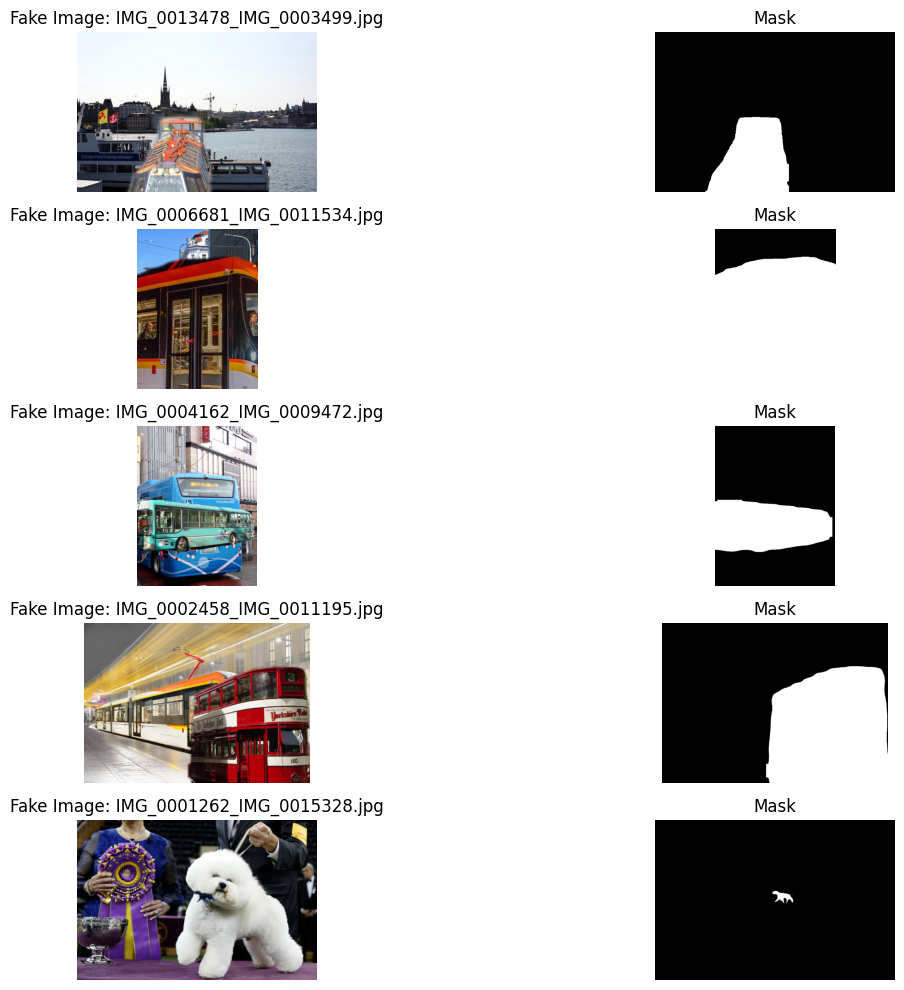

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import random

# === Directory paths ===
root_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/FantasticReality_v1/FantasticReality_v1/dataset"  # <- change this to your dataset root
fake_img_dir = os.path.join(root_dir, "ColorFakeImages")
fake_mask_dir = os.path.join(root_dir, "SegmentationFake")

# === Get list of all fake images ===
fake_images = [f for f in os.listdir(fake_img_dir) if f.endswith(".jpg")]
fake_images.sort()

# === Randomly select 5 samples ===
samples = random.sample(fake_images, 5)

# === Plot 5 image-mask pairs ===
plt.figure(figsize=(15, 10))

for i, img_name in enumerate(samples):
    # Load image
    img_path = os.path.join(fake_img_dir, img_name)
    image = cv2.imread(img_path)
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Load corresponding mask (.npz format)
    mask_name = img_name.replace(".jpg", ".npz")
    mask_path = os.path.join(fake_mask_dir, mask_name)

    if not os.path.exists(mask_path):
        print(f"❌ Missing mask for: {img_name}")
        continue

    # Load npz file and extract 'mask' array
    mask_npz = np.load(mask_path)
    mask = mask_npz['arr_0'] if 'arr_0' in mask_npz else list(mask_npz.values())[0]

    # Resize to match if needed
    if mask.shape[:2] != image.shape[:2]:
        mask = cv2.resize(mask, (image.shape[1], image.shape[0]))

    # Plot image and mask
    plt.subplot(5, 2, 2 * i + 1)
    plt.imshow(image)
    plt.title(f"Fake Image: {img_name}")
    plt.axis("off")

    plt.subplot(5, 2, 2 * i + 2)
    plt.imshow(mask, cmap='gray')
    plt.title("Mask")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf

def iou_bce_loss(y_true, y_pred, smooth=1e-6):
    # Flatten tensors for calculation
    y_true_f = tf.reshape(y_true, [-1])
    y_pred_f = tf.reshape(y_pred, [-1])

    # Binary Crossentropy
    bce = tf.keras.losses.binary_crossentropy(y_true_f, y_pred_f)
    bce_loss = tf.reduce_mean(bce)

    # Intersection Over Union (IoU)
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    total = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f)
    union = total - intersection
    iou = (intersection + smooth) / (union + smooth)
    iou_loss = 1 - iou

    # Combined loss
    return bce_loss + iou_loss

In [ ]:
# # model = tf.keras.models.load_model("final 23-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_dwt_model.h5'",    custom_objects={
# #         "SRMConv2D": SRMConv2D,
# #         "iou_bce_loss": iou_bce_loss
# #     }
# # )


# # def custom_SRMConv2D(**kwargs):
# #     return SRMConv2D(num_classes=1, **kwargs)

# # model = load_model(
# #     "final 23-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_dwt_model.h5",
# #     custom_objects={
# #         "SRMConv2D": SRMConv2D,
# #         "iou_bce_loss": iou_bce_loss
# #     }
# # )

# import tensorflow as tf
# from tensorflow.keras.losses import binary_crossentropy

# # ---- define custom loss ----
# def iou_bce_loss(y_true, y_pred):
#     # BCE
#     bce = binary_crossentropy(y_true, y_pred)

#     # IoU
#     intersection = tf.reduce_sum(y_true * y_pred, axis=[1,2,3])
#     union = tf.reduce_sum(y_true + y_pred, axis=[1,2,3]) - intersection
#     iou = (intersection + 1e-7) / (union + 1e-7)

#     return bce + (1 - iou)

# # ---- load model with custom_objects ----
# from tensorflow.keras.models import load_model

# model = load_model(
#     "final 23-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_dwt_model.h5",
#     custom_objects={
#         "SRMConv2D": SRMConv2D,   # your custom layer
#         "iou_bce_loss": iou_bce_loss
#     }
# )


In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# === SETTINGS ===
root_dir = "/workspace/bhagvan/July2023/image_splicing/extracted_files/FantasticReality_v1/FantasticReality_v1/dataset"
fake_img_dir = os.path.join(root_dir, "ColorFakeImages")
fake_mask_dir = os.path.join(root_dir, "SegmentationFake")

IMG_SIZE = (256, 256)
NUM_DISPLAY = 20   # Number of results to show
NUM_SAVE = 40      # Number of results to save

# === Load model ===
# model_path = "/workspace/bhagvan/models/my_model.h5"   # <-- change this to your model

from tensorflow.keras.models import load_model
from tensorflow.keras.utils import get_custom_objects

# Register custom layer
get_custom_objects().update({"SRMConv2D": SRMConv2D})

# Load the model
# model_path = "/workspace/bhagvan/July2023/models/my_trained_model.h5"
# model = load_model(model_path, custom_objects={"SRMConv2D": SRMConv2D}, compile=False)

print("✅ Model loaded successfully with SRMConv2D")

# model = tf.keras.models.load_model(""/workspace/bhagvan/July2023/image_splicing/21-07-2025 transeanet_aug2025_Component_Comp_AUG2025unet_aug2025.h5", custom_objects={"SRMConv2D": SRMConv2D}, compile=True)

# Extract model and dataset name for saving
# model_name = os.path.splitext(os.path.basename(model_path))[0]

model_name="transeanet_aug2025_Component_Comp_AUG2025_unet"
dataset_name = "fantastic_reality"#os.path.basename(root_dir)
save_dir = f"results_{model_name}_{dataset_name}"
os.makedirs(save_dir, exist_ok=True)

# === List all image files ===
image_files = sorted([f for f in os.listdir(fake_img_dir) if f.endswith('.jpg')])

images, masks = [], []

# === Load dataset ===
for fname in image_files:
    img_path = os.path.join(fake_img_dir, fname)
    img = cv2.imread(img_path)
    if img is None:
        print(f"❌ Failed to read: {img_path}")
        continue
    img = cv2.resize(img, IMG_SIZE)
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)  # Convert to RGB
    img = img.astype(np.float32) / 255.0

    mask_name = fname.replace('.jpg', '.npz')
    mask_path = os.path.join(fake_mask_dir, mask_name)
    if not os.path.exists(mask_path):
        print(f"❌ Missing mask for: {fname}")
        continue
    mask_npz = np.load(mask_path)
    mask = mask_npz['arr_0']
    mask = cv2.resize(mask, IMG_SIZE)
    mask = np.where(mask > 0.5, 1.0, 0.0).astype(np.float32)
    mask = np.expand_dims(mask, axis=-1)

    images.append(img)
    masks.append(mask)

# Convert to arrays
images = np.array(images)
masks = np.array(masks)

print("✅ Loaded images:", images.shape)
print("✅ Loaded masks:", masks.shape)

# === Evaluate ===
loss, *metrics = model.evaluate(images, masks, verbose=1)
print("\n📊 Evaluation Results:")
for name, val in zip(model.metrics_names, [loss] + metrics):
    print(f"{name}: {val:.4f}")

# === Predict ===
pred_masks = model.predict(images[0:100], batch_size=8)
pred_masks = np.where(pred_masks > 0.5, 1.0, 0.0)
# pred_masks_2 = np.where(pred_masks_2 > 0.5, 1.0, 0.0)

# === Display first N results ===
for i in range(min(NUM_DISPLAY, len(images))):
    plt.figure(figsize=(12, 4))

    plt.subplot(1, 3, 1)
    plt.imshow(images[i])
    plt.title("Fake Image")
    plt.axis('off')

    plt.subplot(1, 3, 2)
    plt.imshow(masks[i].squeeze(), cmap='gray')
    plt.title("Ground Truth Mask")
    plt.axis('off')

    plt.subplot(1, 3, 3)
    plt.imshow(pred_masks[i].squeeze(), cmap='gray')
    plt.title("Predicted Mask")
    plt.axis('off')

#     plt.subplot(1, 4, 4)
#     plt.imshow(pred_masks_2[i].squeeze(), cmap='gray')
#     plt.title("Predicted Mask")
#     plt.axis('off')
    plt.tight_layout()
    plt.show()

# === Save first M results ===
for i in range(min(NUM_SAVE, len(images))):
    fig, ax = plt.subplots(1, 3, figsize=(12, 4))

    ax[0].imshow(images[i])
    ax[0].set_title("Fake Image")
    ax[0].axis('off')

    ax[1].imshow(masks[i].squeeze(), cmap='gray')
    ax[1].set_title("Ground Truth")
    ax[1].axis('off')

    ax[2].imshow(pred_masks[i].squeeze(), cmap='gray')
    ax[2].set_title("Predicted")
    ax[2].axis('off')


#     ax[3].imshow(pred_masks_2[i].squeeze(), cmap='gray')
#     ax[3].set_title("Predicted")
#     ax[3].axis('off')

    plt.tight_layout()
    save_path = os.path.join(save_dir, f"result_{i:03d}.png")
    plt.savefig(save_path)
    plt.close(fig)

print(f"✅ Saved {min(NUM_SAVE, len(images))} results in {save_dir}")


In [ ]:
import numpy as np
import tensorflow as tf
import cv2
import random
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, jaccard_score
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# =========================
# Utility: Geometric Transforms
# =========================
def rotate_images(images, k=1):
    return np.array([np.rot90(img, k) for img in images])

def flip_images(images, mode="horizontal"):
    if mode == "horizontal":
        return np.array([np.fliplr(img) for img in images])
    elif mode == "vertical":
        return np.array([np.flipud(img) for img in images])
    else:
        return images

def apply_datagen(images, **kwargs):
    datagen = ImageDataGenerator(**kwargs)
    transformed = []
    for img in images:
        img = np.expand_dims(img, 0)
        transformed.append(next(datagen.flow(img, batch_size=1))[0])
    return np.array(transformed)

# =========================
# Utility: Post-processing Transforms
# =========================
def jpeg_compression(images, quality=30):
    compressed = []
    for img in images:
        encode_param = [int(cv2.IMWRITE_JPEG_QUALITY), quality]
        _, encimg = cv2.imencode('.jpg', (img * 255).astype(np.uint8), encode_param)
        decimg = cv2.imdecode(encimg, 1) / 255.0
        compressed.append(decimg)
    return np.array(compressed)

def add_noise(images, mean=0, std=0.1):
    noisy = images + np.random.normal(mean, std, images.shape)
    return np.clip(noisy, 0, 1)

def blur_images(images, ksize=(5, 5)):
    return np.array([cv2.GaussianBlur(img, ksize, 0) for img in images])

def change_brightness(images, factor=1.5):
    return np.clip(images * factor, 0, 1)

def reduce_colors(images, levels=32):
    return np.floor(images * levels) / levels

def adjust_contrast(images, factor=1.5):
    mean = np.mean(images, axis=(1, 2), keepdims=True)
    return np.clip((images - mean) * factor + mean, 0, 1)

# =========================
# Evaluation Function
# =========================
# def evaluate_model(model, x_data, y_true, name="original"):
#     preds = model.predict(x_data, verbose=0)[0]
#     y_pred = (preds > 0.5).astype(np.uint8).flatten()
#     y_true = y_true.flatten()

#     acc = accuracy_score(y_true, y_pred)
#     prec = precision_score(y_true, y_pred, zero_division=0)
#     rec = recall_score(y_true, y_pred, zero_division=0)
#     f1 = f1_score(y_true, y_pred, zero_division=0)
#     iou = jaccard_score(y_true, y_pred, zero_division=0)
#     try:
#         auc = roc_auc_score(y_true, preds)
#     except:
#         auc = 0.0

#     print(f"\n📊 Evaluation on {name} data")
#     print(f"Accuracy : {acc:.4f}")
#     print(f"Precision: {prec:.4f}")
#     print(f"Recall   : {rec:.4f}")
#     print(f"F1 Score : {f1:.4f}")
#     print(f"IoU      : {iou:.4f}")
#     print(f"AUC      : {auc:.4f}")

#     return {
#         "accuracy": acc,
#         "precision": prec,
#         "recall": rec,
#         "f1_score": f1,
#         "iou": iou,
#         "auc": auc
#     }

# =========================
# Create datasets
# =========================
# Geometric
test_x_rot90  = rotate_images(test_x, k=1)
test_x_rot180 = rotate_images(test_x, k=2)
test_x_rot270 = rotate_images(test_x, k=3)
test_x_flip_h = flip_images(test_x, mode="horizontal")
test_x_flip_v = flip_images(test_x, mode="vertical")
test_x_shift_w = apply_datagen(test_x, width_shift_range=0.2)
test_x_shift_h = apply_datagen(test_x, height_shift_range=0.2)
test_x_zoom   = apply_datagen(test_x, zoom_range=0.3)
test_x_shear  = apply_datagen(test_x, shear_range=20)

# Post-processing
test_x_jpeg   = jpeg_compression(test_x, quality=30)
test_x_noise  = add_noise(test_x, std=0.1)
test_x_blur   = blur_images(test_x)
test_x_bright = change_brightness(test_x, factor=1.5)
test_x_color  = reduce_colors(test_x, levels=32)
test_x_contrast = adjust_contrast(test_x, factor=1.5)

# =========================


In [ ]:
import pandas as pd

def evaluate_model(model, x, y, description=""):
    """
    Evaluates the given model on test data (x, y) and returns results as a dictionary.

    Args:
        model: Trained Keras model.
        x: Test images / input data.
        y: Ground truth labels.
        description (str): Description for logging (e.g., 'Rotated 90°').

    Returns:
        dict: Dictionary mapping metric names -> values.
    """
    print(f"\n📊 Evaluating on {description} dataset...")
    results = model.evaluate(x, y, verbose=0)  # silent eval

    # model.metrics_names includes "loss" + metrics defined during compile
    metrics_dict = {name: val for name, val in zip(model.metrics_names, results)}

    # Optional: pretty print
    for k, v in metrics_dict.items():
        print(f"{description} - {k}: {v:.4f}")

    return metrics_dict


In [ ]:
# results["Original"]   = evaluate_model(model, test_x, test_y, "Original")
results={}
results["Rot90"]      = evaluate_model(model, test_x_rot90, test_y, "Rotated 90°")
results["Rot180"]     = evaluate_model(model, test_x_rot180, test_y, "Rotated 180°")
results["Rot270"]     = evaluate_model(model, test_x_rot270, test_y, "Rotated 270°")
results["Flip_H"]     = evaluate_model(model, test_x_flip_h, test_y, "Horizontal Flip")
results["Flip_V"]     = evaluate_model(model, test_x_flip_v, test_y, "Vertical Flip")
results["Shift_W"]    = evaluate_model(model, test_x_shift_w, test_y, "Width Shift")
results["Shift_H"]    = evaluate_model(model, test_x_shift_h, test_y, "Height Shift")
results["Zoom"]       = evaluate_model(model, test_x_zoom, test_y, "Zoom")
results["Shear"]      = evaluate_model(model, test_x_shear, test_y, "Shear")

# Post-processing
results["JPEG"]       = evaluate_model(model, test_x_jpeg, test_y, "JPEG Compression")
results["Noise"]      = evaluate_model(model, test_x_noise, test_y, "Gaussian Noise")
results["Blur"]       = evaluate_model(model, test_x_blur, test_y, "Image Blur")
results["Brightness"] = evaluate_model(model, test_x_bright, test_y, "Brightness Change")
results["Color_Red"]  = evaluate_model(model, test_x_color, test_y, "Color Reduction")
results["Contrast"]   = evaluate_model(model, test_x_contrast, test_y, "Contrast Adjustment")

# =========================
# Save results as DataFrame
# =========================
df_results = pd.DataFrame(results).T
print("\n===== Comparison Table =====")
print(df_results)
df_results.to_csv("full_robustness_transeanet_aug2025_Component_Comp_AUG2025unet_aug2025_evaluation.csv", index=True)


📊 Evaluating on Rotated 90° dataset...
Rotated 90° - loss: 1.9535
Rotated 90° - accuracy: 0.9011
Rotated 90° - precision: 0.1147
Rotated 90° - recall: 0.1295
Rotated 90° - auc: 0.5416
Rotated 90° - tp: 903056.0000
Rotated 90° - tn: 118507856.0000
Rotated 90° - fp: 6968451.0000
Rotated 90° - fn: 6068896.0000
Rotated 90° - iou: 0.0639
Rotated 90° - f1_score: 0.1202

📊 Evaluating on Rotated 180° dataset...
Rotated 180° - loss: 2.0131
Rotated 180° - accuracy: 0.9002
Rotated 180° - precision: 0.0811
Rotated 180° - recall: 0.0863
Rotated 180° - auc: 0.5182
Rotated 180° - tp: 601659.0000
Rotated 180° - tn: 118663400.0000
Rotated 180° - fp: 6812894.0000
Rotated 180° - fn: 6370293.0000
Rotated 180° - iou: 0.0432
Rotated 180° - f1_score: 0.0828

📊 Evaluating on Rotated 270° dataset...
Rotated 270° - loss: 1.9475
Rotated 270° - accuracy: 0.9012
Rotated 270° - precision: 0.1178
Rotated 270° - recall: 0.1338
Rotated 270° - auc: 0.5436
Rotated 270° - tp: 932562.0000
Rotated 270° - tn: 118489184.000